<a href="https://colab.research.google.com/github/pdtarricone/analytics_portfolio/blob/PDT_Analytics_Portfolio/Subscriber_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import scipy.stats as stats
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns

# Configure plot styles
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["font.size"] = 12

print("Analysis environment set up successfully.")

Analysis environment set up successfully.


In [35]:
from IPython.display import display, Markdown

report = """
# Subscriber Churn & Engagement: Executive Analysis and Recommendations

## 1. Key Insights & Findings

### A. Engagement is the Strongest Predictor of Retention
* **The Data:** Retained subscribers have significantly higher **Engagement Scores** (concentrating in the 30-80 range) compared to churned subscribers, who heavily cluster at the bottom (0-25 range).
* **The Tier Breakdown:** In the **Basic-Ads** tier, subscribers classified as *Checked Out* have a **55.79%** churn rate, whereas *Obsessed* users churn at only **7.95%**. This dramatic drop highlights that keeping users active is the single best way to secure their subscription.

### B. Price Increases Fuel Churn, Especially in Basic Tiers
* **The Data:** Subscribers subjected to a price increase exhibit a **49.52%** churn rate compared to **30.97%** for those with no price increase.
* **Standard & Basic Vulnerability:** The **Basic-Ads** tier with a price increase has an astronomical churn rate of **56.48%**. For **Standard**, it is **46.85%**. Even **Premium** users spike from ~19.6% to **34.0%** churn when prices go up.

### C. Onboarding & Acquisition Channels Dictate Lifetime Value
* **Free Trials & Paid Social are High-Risk:** Free Trial users hit an alarming **70.5%** churn rate during the 181-365 days window. Paid Social follows a similar pattern with **67.2%** churn in that same timeline.
* **Bundles & Referrals are Highly Sticky:** Bundled subscriptions maintain exceptionally low churn rates throughout their lifecycle (e.g., only **7.0%** churn in the first 90 days and remaining under 25% overall).

### D. Customer Support Pain Points
* **The Support Paradox:** Interestingly, subscribers who *have* raised support tickets have a *lower* churn rate (**30.48%**) than those who haven't (**51.56%**). This suggests that reaching out is a form of engagement, and successful resolution preserves the customer.
* **CSAT & Retention:** Retained customers report an average CSAT score of **3.86/5**, while churned users averaged only **2.86/5**, indicating that poor support interactions directly trigger cancellations.

---

## 2. Strategic Recommendations & Action Items

### 1. Implement Proactive Engagement Triggers
* **Action:** Build automated email/push campaigns triggered when a subscriber's engagement score drops into the *Slowing Down* or *Checked Out* threshold (e.g., no watch history for 7 consecutive days).
* **Offer:** Deliver personalized content recommendations based on historical categories or highlight trending exclusive content to pull them back.

### 2. Redesign the Price Increase Playbook
* **Action:** Avoid blanket price hikes on the **Basic-Ads** tier. If price adjustments are mandatory, introduce a temporary grace discount (e.g., 'Keep your old rate for 3 more months') or bundle premium features temporarily to justify the value increment.
* **Target:** Target price adjustments primarily towards highly engaged *Obsessed* users who show a much lower price sensitivity.

### 3. Optimize the Post-Trial Nurture Sequence
* **Action:** Create a targeted "Day 90 to 180" onboarding phase specifically for Free Trial and Paid Social sign-ups. Since their churn spikes massively in the 181-365 days window, prioritize milestone-based offers or annual contract discounts around day 120.

### 4. Enhance Support Resolution Protocols
* **Action:** Since raising a ticket correlates with retention, make customer service easily accessible. Ensure agents are trained to aggressively resolve issues for users with low CSAT history, utilizing retention incentives (e.g., one-month billing credits) when resolving critical "Streaming Quality" or "Billing" disputes.
"""

display(Markdown(report))


# Subscriber Churn & Engagement: Executive Analysis and Recommendations

## 1. Key Insights & Findings

### A. Engagement is the Strongest Predictor of Retention
* **The Data:** Retained subscribers have significantly higher **Engagement Scores** (concentrating in the 30-80 range) compared to churned subscribers, who heavily cluster at the bottom (0-25 range).
* **The Tier Breakdown:** In the **Basic-Ads** tier, subscribers classified as *Checked Out* have a **55.79%** churn rate, whereas *Obsessed* users churn at only **7.95%**. This dramatic drop highlights that keeping users active is the single best way to secure their subscription.

### B. Price Increases Fuel Churn, Especially in Basic Tiers
* **The Data:** Subscribers subjected to a price increase exhibit a **49.52%** churn rate compared to **30.97%** for those with no price increase.
* **Standard & Basic Vulnerability:** The **Basic-Ads** tier with a price increase has an astronomical churn rate of **56.48%**. For **Standard**, it is **46.85%**. Even **Premium** users spike from ~19.6% to **34.0%** churn when prices go up.

### C. Onboarding & Acquisition Channels Dictate Lifetime Value
* **Free Trials & Paid Social are High-Risk:** Free Trial users hit an alarming **70.5%** churn rate during the 181-365 days window. Paid Social follows a similar pattern with **67.2%** churn in that same timeline.
* **Bundles & Referrals are Highly Sticky:** Bundled subscriptions maintain exceptionally low churn rates throughout their lifecycle (e.g., only **7.0%** churn in the first 90 days and remaining under 25% overall).

### D. Customer Support Pain Points
* **The Support Paradox:** Interestingly, subscribers who *have* raised support tickets have a *lower* churn rate (**30.48%**) than those who haven't (**51.56%**). This suggests that reaching out is a form of engagement, and successful resolution preserves the customer.
* **CSAT & Retention:** Retained customers report an average CSAT score of **3.86/5**, while churned users averaged only **2.86/5**, indicating that poor support interactions directly trigger cancellations.

---

## 2. Strategic Recommendations & Action Items

### 1. Implement Proactive Engagement Triggers
* **Action:** Build automated email/push campaigns triggered when a subscriber's engagement score drops into the *Slowing Down* or *Checked Out* threshold (e.g., no watch history for 7 consecutive days).
* **Offer:** Deliver personalized content recommendations based on historical categories or highlight trending exclusive content to pull them back.

### 2. Redesign the Price Increase Playbook
* **Action:** Avoid blanket price hikes on the **Basic-Ads** tier. If price adjustments are mandatory, introduce a temporary grace discount (e.g., 'Keep your old rate for 3 more months') or bundle premium features temporarily to justify the value increment.
* **Target:** Target price adjustments primarily towards highly engaged *Obsessed* users who show a much lower price sensitivity.

### 3. Optimize the Post-Trial Nurture Sequence
* **Action:** Create a targeted "Day 90 to 180" onboarding phase specifically for Free Trial and Paid Social sign-ups. Since their churn spikes massively in the 181-365 days window, prioritize milestone-based offers or annual contract discounts around day 120.

### 4. Enhance Support Resolution Protocols
* **Action:** Since raising a ticket correlates with retention, make customer service easily accessible. Ensure agents are trained to aggressively resolve issues for users with low CSAT history, utilizing retention incentives (e.g., one-month billing credits) when resolving critical "Streaming Quality" or "Billing" disputes.


In [2]:
# let colab access my google drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
try:
    df_subscribers = pd.read_csv('/content/drive/MyDrive/subscribers.csv')
    df_billing = pd.read_csv('/content/drive/MyDrive/billing.csv')
    df_plan_changes = pd.read_csv('/content/drive/MyDrive/plan_changes.csv')
    df_support_tickets = pd.read_csv('/content/drive/MyDrive/support_tickets.csv')
    df_watch_history = pd.read_csv('/content/drive/MyDrive/watch_history.csv')

    print("DataFrames loaded successfully.")
    print("\nShapes of the loaded DataFrames:")
    print(f"df_subscribers: {df_subscribers.shape}")
    print(f"df_billing: {df_billing.shape}")
    print(f"df_plan_changes: {df_plan_changes.shape}")
    print(f"df_support_tickets: {df_support_tickets.shape}")
    print(f"df_watch_history: {df_watch_history.shape}")

except FileNotFoundError as e:
    print(f"Error loading file: {e}. Please ensure all CSV files are in your Drive directory.")
except Exception as e:
    print(f"An unexpected error occurred: {e}")

DataFrames loaded successfully.

Shapes of the loaded DataFrames:
df_subscribers: (10000, 15)
df_billing: (80809, 9)
df_plan_changes: (4554, 7)
df_support_tickets: (3056, 8)
df_watch_history: (306935, 10)


In [4]:
dataframes = {
    "df_subscribers": df_subscribers,
    "df_billing": df_billing,
    "df_plan_changes": df_plan_changes,
    "df_support_tickets": df_support_tickets,
    "df_watch_history": df_watch_history
}

for name, df in dataframes.items():
    print(f"\n--- {name} ---")
    print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")
    display(df.head())


--- df_subscribers ---
Rows: 10000, Columns: 15


,subscriber_id,account_id,age,gender,region,country,signup_date,current_plan,signup_channel,device_primary,household_size,churn_status,churn_date,price_increase_flag,is_resub
0,SUB_000001,ACC_000001,44.0,Male,North America,CA,2022-12-15,Standard,Referral,Mobile,1.0,0,NaN,0,0
1,SUB_000002,ACC_000002,NaN,Male,Western Europe,DE,2026-01-30,Basic-Ads,Free Trial,Mobile,2.0,1,2026-02-21,1,0
2,SUB_000003,ACC_000003,32.0,Female,North America,US,2024-02-25,Premium,Paid Social,TV,4.0,0,NaN,0,0
3,SUB_000004,ACC_000004,33.0,Male,North America,US,2024-06-24,Basic-Ads,Paid Social,TV,2.0,1,2026-01-13,1,0
4,SUB_000005,ACC_000005,32.0,Undisclosed,North America,US,2025-11-28,Basic-Ads,Paid Social,TV,NaN,1,2026-02-28,0,0



--- df_billing ---
Rows: 80809, Columns: 9


,transaction_id,subscriber_id,billing_date,plan_at_billing,amount,payment_status,payment_method,retry_count,discount_applied
0,TXN_00000001,SUB_000001,2025-03-31,Standard,17.99,Success,Credit Card,0,0
1,TXN_00000002,SUB_000001,2025-04-30,Standard,17.99,Success,Credit Card,0,0
2,TXN_00000003,SUB_000001,2025-05-30,Standard,17.99,Success,Credit Card,0,0
3,TXN_00000004,SUB_000001,2025-06-29,Standard,17.99,Success,Credit Card,0,0
4,TXN_00000005,SUB_000001,2025-07-29,Standard,17.99,Success,Credit Card,0,0



--- df_plan_changes ---
Rows: 4554, Columns: 7


,change_id,subscriber_id,change_date,from_plan,to_plan,change_type,reason_code
0,CHG_000001,SUB_000002,2026-02-21,Basic-Ads,(cancelled),Cancellation,Content
1,CHG_000002,SUB_000004,2026-01-13,Basic-Ads,(cancelled),Cancellation,Service
2,CHG_000003,SUB_000005,2026-02-28,Basic-Ads,(cancelled),Cancellation,Content
3,CHG_000004,SUB_000006,2026-03-05,Basic-Ads,(cancelled),Cancellation,Cost
4,CHG_000005,SUB_000011,2025-08-12,Standard,(cancelled),Cancellation,Service



--- df_support_tickets ---
Rows: 3056, Columns: 8


,ticket_id,subscriber_id,ticket_date,issue_category,resolution_status,resolution_time_hours,csat_score,contact_channel
0,TKT_000001,SUB_000003,2025-09-05,Streaming Quality,Resolved,1.4,NaN,Email
1,TKT_000002,SUB_000003,2025-05-28,Billing,Resolved,47.0,4.0,Chat
2,TKT_000003,SUB_000005,2025-12-06,Account Access,Resolved,2.8,5.0,Email
3,TKT_000004,SUB_000016,2026-03-29,Content Request,Resolved,47.7,5.0,In-App
4,TKT_000005,SUB_000019,2025-09-25,Content Request,Resolved,17.5,NaN,In-App



--- df_watch_history ---
Rows: 306935, Columns: 10


,session_id,subscriber_id,session_date,content_id,content_category,content_length_minutes,watch_duration_minutes,completion_pct,device_used,time_of_day
0,SES_00000001,SUB_000001,2025-08-13,CNT_00945,Licensed Movies,107,106,0.993,Mobile,Morning
1,SES_00000002,SUB_000001,2026-02-20,CNT_21098,Live Sports,120,71,0.599,Mobile,Evening
2,SES_00000003,SUB_000001,2025-04-22,CNT_49631,Ad-Supported Catalog,43,37,0.865,Mobile,Evening
3,SES_00000004,SUB_000001,2025-08-02,CNT_34829,Originals,50,30,0.614,Mobile,Evening
4,SES_00000005,SUB_000001,2025-04-05,CNT_23324,Ad-Supported Catalog,46,34,0.744,Mobile,Evening


In [5]:
dataframes = {
    "df_subscribers": df_subscribers,
    "df_billing": df_billing,
    "df_plan_changes": df_plan_changes,
    "df_support_tickets": df_support_tickets,
    "df_watch_history": df_watch_history
}

for name, df in dataframes.items():
    print(f"\n--- Data Quality Check for {name} ---")

    # Check for Missing Values
    missing_values = df.isnull().sum()
    missing_values = missing_values[missing_values > 0]
    if not missing_values.empty:
        print("\nMissing Values per column:")
        print(missing_values)
    else:
        print("\nNo missing values found.")

    # Check for Duplicate Values
    duplicate_rows = df.duplicated().sum()
    if duplicate_rows > 0:
        print(f"\nNumber of duplicate rows: {duplicate_rows}")
    else:
        print("\nNo duplicate rows found.")

    # Check Data Types
    print("\nData Types:")
    print(df.dtypes)
    print("\n")


--- Data Quality Check for df_subscribers ---

Missing Values per column:
age                279
gender             449
device_primary     197
household_size    1222
churn_date        6499
dtype: int64

No duplicate rows found.

Data Types:
subscriber_id           object
account_id              object
age                    float64
gender                  object
region                  object
country                 object
signup_date             object
current_plan            object
signup_channel          object
device_primary          object
household_size         float64
churn_status             int64
churn_date              object
price_increase_flag      int64
is_resub                 int64
dtype: object



--- Data Quality Check for df_billing ---

No missing values found.

No duplicate rows found.

Data Types:
transaction_id       object
subscriber_id        object
billing_date         object
plan_at_billing      object
amount              float64
payment_status       object
p

In [6]:
dataframes = {
    "df_subscribers": df_subscribers,
    "df_billing": df_billing,
    "df_plan_changes": df_plan_changes,
    "df_support_tickets": df_support_tickets,
    "df_watch_history": df_watch_history
}

for name, df in dataframes.items():
    print(f"\n--- Descriptive Statistics for {name} ---")
    display(df.describe(include='all'))


--- Descriptive Statistics for df_subscribers ---


,subscriber_id,account_id,age,gender,region,country,signup_date,current_plan,signup_channel,device_primary,household_size,churn_status,churn_date,price_increase_flag,is_resub
count,10000,10000,9721.000000,9551,10000,10000,10000,10000,10000,9803,8778.000000,10000.000000,3501,10000.00000,10000.000000
unique,10000,9434,NaN,4,2,8,1448,3,6,4,NaN,NaN,366,NaN,NaN
top,SUB_009984,ACC_009212,NaN,Female,North America,US,2026-03-06,Basic-Ads,Free Trial,TV,NaN,NaN,2026-03-30,NaN,NaN
freq,1,3,NaN,4264,5996,4978,30,4846,2287,4790,NaN,NaN,35,NaN,NaN
mean,NaN,NaN,40.184137,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.415812,0.350100,NaN,0.21790,0.061800
std,NaN,NaN,13.906842,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.315991,0.477025,NaN,0.41284,0.240804
min,NaN,NaN,18.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,0.000000,NaN,0.00000,0.000000
25%,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,0.000000,NaN,0.00000,0.000000
50%,NaN,NaN,39.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.000000,0.000000,NaN,0.00000,0.000000
75%,NaN,NaN,51.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.000000,1.000000,NaN,0.00000,0.000000



--- Descriptive Statistics for df_billing ---


,transaction_id,subscriber_id,billing_date,plan_at_billing,amount,payment_status,payment_method,retry_count,discount_applied
count,80809,80809,80809,80809,80809.000000,80809,80809,80809.000000,80809.000000
unique,80809,10000,366,3,NaN,4,6,NaN,NaN
top,TXN_00080809,SUB_009981,2025-03-31,Basic-Ads,NaN,Success,Credit Card,NaN,NaN
freq,1,13,5617,35293,NaN,78192,42210,NaN,NaN
mean,NaN,NaN,NaN,NaN,14.584139,NaN,NaN,0.045020,0.121026
std,NaN,NaN,NaN,NaN,6.537780,NaN,NaN,0.293526,0.326160
min,NaN,NaN,NaN,NaN,6.390000,NaN,NaN,0.000000,0.000000
25%,NaN,NaN,NaN,NaN,7.990000,NaN,NaN,0.000000,0.000000
50%,NaN,NaN,NaN,NaN,17.990000,NaN,NaN,0.000000,0.000000
75%,NaN,NaN,NaN,NaN,17.990000,NaN,NaN,0.000000,0.000000



--- Descriptive Statistics for df_plan_changes ---


,change_id,subscriber_id,change_date,from_plan,to_plan,change_type,reason_code
count,4554,4554,4554,4554,4554,4554,4554
unique,4554,4202,366,4,4,4,6
top,CHG_004554,SUB_009994,2026-03-30,Basic-Ads,(cancelled),Cancellation,Cost
freq,1,2,43,2194,3501,3501,1648



--- Descriptive Statistics for df_support_tickets ---


,ticket_id,subscriber_id,ticket_date,issue_category,resolution_status,resolution_time_hours,csat_score,contact_channel
count,3056,3056,3056,3056,3056,3056.000000,2004.000000,3056
unique,3056,2149,366,5,4,NaN,NaN,4
top,TKT_003040,SUB_009782,2026-03-25,Streaming Quality,Resolved,NaN,NaN,In-App
freq,1,4,27,892,1852,NaN,NaN,1294
mean,NaN,NaN,NaN,NaN,NaN,20.224673,3.341317,NaN
std,NaN,NaN,NaN,NaN,NaN,23.644539,1.487263,NaN
min,NaN,NaN,NaN,NaN,NaN,0.500000,1.000000,NaN
25%,NaN,NaN,NaN,NaN,NaN,6.300000,2.000000,NaN
50%,NaN,NaN,NaN,NaN,NaN,12.400000,4.000000,NaN
75%,NaN,NaN,NaN,NaN,NaN,24.200000,5.000000,NaN



--- Descriptive Statistics for df_watch_history ---


,session_id,subscriber_id,session_date,content_id,content_category,content_length_minutes,watch_duration_minutes,completion_pct,device_used,time_of_day
count,306935,306935,306935,306935,306935,306935.000000,306935.000000,306935.000000,301907,306935
unique,306935,9865,366,49896,5,NaN,NaN,NaN,4,4
top,SES_00306935,SUB_003615,2026-02-28,CNT_20822,Licensed Movies,NaN,NaN,NaN,TV,Evening
freq,1,100,986,18,96917,NaN,NaN,NaN,148854,153458
mean,NaN,NaN,NaN,NaN,NaN,74.577269,48.860599,0.661673,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,38.115064,30.159776,0.197782,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,15.000000,0.000000,0.050000,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,45.000000,26.000000,0.536000,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,60.000000,41.000000,0.693000,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,105.000000,68.000000,0.816000,NaN,NaN


In [7]:
dataframes = {
    "df_subscribers": df_subscribers,
    "df_billing": df_billing,
    "df_plan_changes": df_plan_changes,
    "df_support_tickets": df_support_tickets,
    "df_watch_history": df_watch_history
}

for name, df in dataframes.items():
    print(f"\n--- Data Quality Check for {name} ---")

    # Check for Missing Values
    missing_values = df.isnull().sum()
    missing_values = missing_values[missing_values > 0]
    if not missing_values.empty:
        print("\nMissing Values per column:")
        print(missing_values)
    else:
        print("\nNo missing values found.")

    # Check for Duplicate Values
    duplicate_rows = df.duplicated().sum()
    if duplicate_rows > 0:
        print(f"\nNumber of duplicate rows: {duplicate_rows}")
    else:
        print("\nNo duplicate rows found.")

    # Check Data Types
    print("\nData Types:")
    print(df.dtypes)
    print("\n")


--- Data Quality Check for df_subscribers ---

Missing Values per column:
age                279
gender             449
device_primary     197
household_size    1222
churn_date        6499
dtype: int64

No duplicate rows found.

Data Types:
subscriber_id           object
account_id              object
age                    float64
gender                  object
region                  object
country                 object
signup_date             object
current_plan            object
signup_channel          object
device_primary          object
household_size         float64
churn_status             int64
churn_date              object
price_increase_flag      int64
is_resub                 int64
dtype: object



--- Data Quality Check for df_billing ---

No missing values found.

No duplicate rows found.

Data Types:
transaction_id       object
subscriber_id        object
billing_date         object
plan_at_billing      object
amount              float64
payment_status       object
p

In [8]:
dataframes = {
    "df_subscribers": df_subscribers,
    "df_billing": df_billing,
    "df_plan_changes": df_plan_changes,
    "df_support_tickets": df_support_tickets,
    "df_watch_history": df_watch_history
}

for name, df in dataframes.items():
    print(f"\n--- Descriptive Statistics for {name} ---")
    display(df.describe(include='all'))


--- Descriptive Statistics for df_subscribers ---


,subscriber_id,account_id,age,gender,region,country,signup_date,current_plan,signup_channel,device_primary,household_size,churn_status,churn_date,price_increase_flag,is_resub
count,10000,10000,9721.000000,9551,10000,10000,10000,10000,10000,9803,8778.000000,10000.000000,3501,10000.00000,10000.000000
unique,10000,9434,NaN,4,2,8,1448,3,6,4,NaN,NaN,366,NaN,NaN
top,SUB_009984,ACC_009212,NaN,Female,North America,US,2026-03-06,Basic-Ads,Free Trial,TV,NaN,NaN,2026-03-30,NaN,NaN
freq,1,3,NaN,4264,5996,4978,30,4846,2287,4790,NaN,NaN,35,NaN,NaN
mean,NaN,NaN,40.184137,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.415812,0.350100,NaN,0.21790,0.061800
std,NaN,NaN,13.906842,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.315991,0.477025,NaN,0.41284,0.240804
min,NaN,NaN,18.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,0.000000,NaN,0.00000,0.000000
25%,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,0.000000,NaN,0.00000,0.000000
50%,NaN,NaN,39.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.000000,0.000000,NaN,0.00000,0.000000
75%,NaN,NaN,51.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.000000,1.000000,NaN,0.00000,0.000000



--- Descriptive Statistics for df_billing ---


,transaction_id,subscriber_id,billing_date,plan_at_billing,amount,payment_status,payment_method,retry_count,discount_applied
count,80809,80809,80809,80809,80809.000000,80809,80809,80809.000000,80809.000000
unique,80809,10000,366,3,NaN,4,6,NaN,NaN
top,TXN_00080809,SUB_009981,2025-03-31,Basic-Ads,NaN,Success,Credit Card,NaN,NaN
freq,1,13,5617,35293,NaN,78192,42210,NaN,NaN
mean,NaN,NaN,NaN,NaN,14.584139,NaN,NaN,0.045020,0.121026
std,NaN,NaN,NaN,NaN,6.537780,NaN,NaN,0.293526,0.326160
min,NaN,NaN,NaN,NaN,6.390000,NaN,NaN,0.000000,0.000000
25%,NaN,NaN,NaN,NaN,7.990000,NaN,NaN,0.000000,0.000000
50%,NaN,NaN,NaN,NaN,17.990000,NaN,NaN,0.000000,0.000000
75%,NaN,NaN,NaN,NaN,17.990000,NaN,NaN,0.000000,0.000000



--- Descriptive Statistics for df_plan_changes ---


,change_id,subscriber_id,change_date,from_plan,to_plan,change_type,reason_code
count,4554,4554,4554,4554,4554,4554,4554
unique,4554,4202,366,4,4,4,6
top,CHG_004554,SUB_009994,2026-03-30,Basic-Ads,(cancelled),Cancellation,Cost
freq,1,2,43,2194,3501,3501,1648



--- Descriptive Statistics for df_support_tickets ---


,ticket_id,subscriber_id,ticket_date,issue_category,resolution_status,resolution_time_hours,csat_score,contact_channel
count,3056,3056,3056,3056,3056,3056.000000,2004.000000,3056
unique,3056,2149,366,5,4,NaN,NaN,4
top,TKT_003040,SUB_009782,2026-03-25,Streaming Quality,Resolved,NaN,NaN,In-App
freq,1,4,27,892,1852,NaN,NaN,1294
mean,NaN,NaN,NaN,NaN,NaN,20.224673,3.341317,NaN
std,NaN,NaN,NaN,NaN,NaN,23.644539,1.487263,NaN
min,NaN,NaN,NaN,NaN,NaN,0.500000,1.000000,NaN
25%,NaN,NaN,NaN,NaN,NaN,6.300000,2.000000,NaN
50%,NaN,NaN,NaN,NaN,NaN,12.400000,4.000000,NaN
75%,NaN,NaN,NaN,NaN,NaN,24.200000,5.000000,NaN



--- Descriptive Statistics for df_watch_history ---


,session_id,subscriber_id,session_date,content_id,content_category,content_length_minutes,watch_duration_minutes,completion_pct,device_used,time_of_day
count,306935,306935,306935,306935,306935,306935.000000,306935.000000,306935.000000,301907,306935
unique,306935,9865,366,49896,5,NaN,NaN,NaN,4,4
top,SES_00306935,SUB_003615,2026-02-28,CNT_20822,Licensed Movies,NaN,NaN,NaN,TV,Evening
freq,1,100,986,18,96917,NaN,NaN,NaN,148854,153458
mean,NaN,NaN,NaN,NaN,NaN,74.577269,48.860599,0.661673,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,38.115064,30.159776,0.197782,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,15.000000,0.000000,0.050000,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,45.000000,26.000000,0.536000,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,60.000000,41.000000,0.693000,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,105.000000,68.000000,0.816000,NaN,NaN


In [9]:
# Convert date columns in df_subscribers
df_subscribers['signup_date'] = pd.to_datetime(df_subscribers['signup_date'], errors='coerce')
df_subscribers['churn_date'] = pd.to_datetime(df_subscribers['churn_date'], errors='coerce')

# Convert date columns in df_billing
df_billing['billing_date'] = pd.to_datetime(df_billing['billing_date'], errors='coerce')

# Convert date columns in df_plan_changes
df_plan_changes['change_date'] = pd.to_datetime(df_plan_changes['change_date'], errors='coerce')

# Convert date columns in df_support_tickets
df_support_tickets['ticket_date'] = pd.to_datetime(df_support_tickets['ticket_date'], errors='coerce')

# Convert date columns in df_watch_history
df_watch_history['session_date'] = pd.to_datetime(df_watch_history['session_date'], errors='coerce')

print("Date columns have been converted to datetime format.")

# Verify data types
print("\n--- Verified Data Types after Conversion ---")
print("df_subscribers date columns:")
print(df_subscribers[['signup_date', 'churn_date']].dtypes)
print("\ndf_billing date column:")
print(df_billing['billing_date'].dtypes)
print("\ndf_plan_changes date column:")
print(df_plan_changes['change_date'].dtypes)
print("\ndf_support_tickets date column:")
print(df_support_tickets['ticket_date'].dtypes)
print("\ndf_watch_history date column:")
print(df_watch_history['session_date'].dtypes)

Date columns have been converted to datetime format.

--- Verified Data Types after Conversion ---
df_subscribers date columns:
signup_date    datetime64[ns]
churn_date     datetime64[ns]
dtype: object

df_billing date column:
datetime64[ns]

df_plan_changes date column:
datetime64[ns]

df_support_tickets date column:
datetime64[ns]

df_watch_history date column:
datetime64[ns]


In [10]:
watch_summary = df_watch_history.groupby('subscriber_id').agg(
    total_watch_duration_minutes=('watch_duration_minutes', 'sum'),
    distinct_session_dates=('session_date', 'nunique'),
    unique_content_categories=('content_category', 'nunique')
).reset_index()

# Normalize each metric to a 0-1 scale
for col in ['total_watch_duration_minutes', 'distinct_session_dates', 'unique_content_categories']:
    min_val = watch_summary[col].min()
    max_val = watch_summary[col].max()
    if max_val == min_val:
        watch_summary[f'{col}_normalized'] = 0  # Avoid division by zero if all values are the same
    else:
        watch_summary[f'{col}_normalized'] = (watch_summary[col] - min_val) / (max_val - min_val)

# Calculate weighted average for engagement score (0-1 scale)
watch_summary['engagement_score_normalized'] = (
    0.50 * watch_summary['total_watch_duration_minutes_normalized'] +
    0.30 * watch_summary['distinct_session_dates_normalized'] +
    0.20 * watch_summary['unique_content_categories_normalized']
)

# Scale the engagement score to a fixed range between 0 and 100
watch_summary['engagement_score'] = watch_summary['engagement_score_normalized'] * 100

# Display a sample of the results and basic statistics
print("Engagement Score Calculation Complete. Sample Results:")
display(watch_summary[['subscriber_id', 'total_watch_duration_minutes', 'distinct_session_dates', 'unique_content_categories', 'engagement_score']].head())

print("\nEngagement Score Statistics:")
print(watch_summary['engagement_score'].describe())

Engagement Score Calculation Complete. Sample Results:


,subscriber_id,total_watch_duration_minutes,distinct_session_dates,unique_content_categories,engagement_score
0,SUB_000001,2931,44,5,50.348461
1,SUB_000002,23,1,1,0.124830
2,SUB_000003,2553,48,5,49.480254
3,SUB_000004,513,14,5,27.054066
4,SUB_000005,1337,36,5,38.750785



Engagement Score Statistics:
count    9865.000000
mean       32.487277
std        21.710127
min         0.000000
25%        15.512188
50%        29.563410
75%        45.945447
max        98.360263
Name: engagement_score, dtype: float64


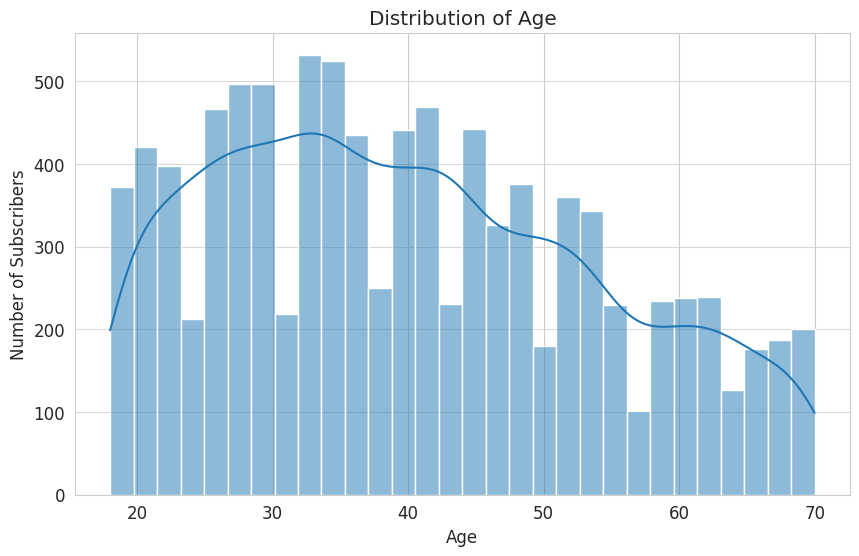


Age Statistics:
count    9721.000000
mean       40.184137
std        13.906842
min        18.000000
25%        29.000000
50%        39.000000
75%        51.000000
max        70.000000
Name: age, dtype: float64


In [11]:
plt.figure(figsize=(10, 6))
sns.histplot(df_subscribers['age'].dropna(), bins=30, kde=True)
plt.title('Distribution of Age')
plt.xlabel('Age')
plt.ylabel('Number of Subscribers')
plt.grid(axis='y', alpha=0.75)
plt.show()

print("\nAge Statistics:")
print(df_subscribers['age'].describe())

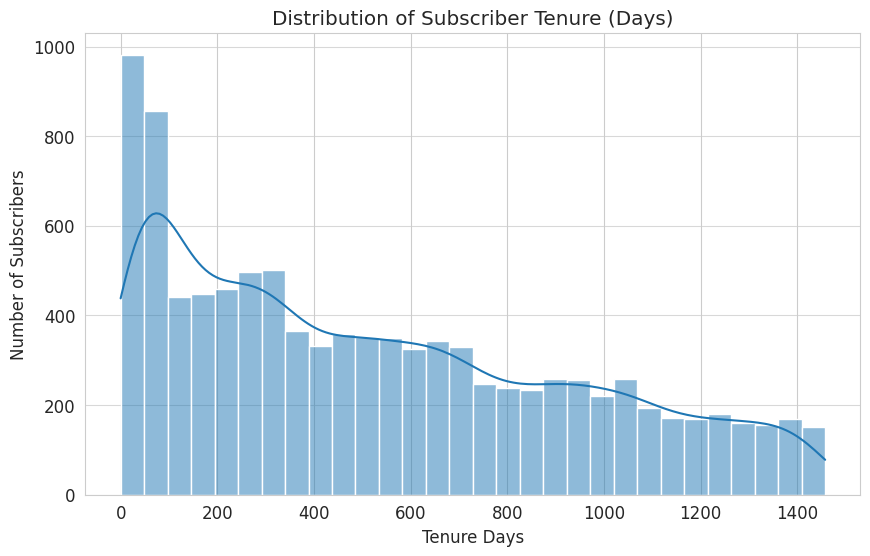

In [12]:
# Ensure signup_date is converted to datetime
df_subscribers['signup_date'] = pd.to_datetime(df_subscribers['signup_date'], errors='coerce')

# Define 'today' as the latest signup date in the dataset for a consistent reference point
today_date = df_subscribers['signup_date'].max()

# Calculate tenure in days
df_subscribers['tenure_days'] = (today_date - df_subscribers['signup_date']).dt.days

# Visualize the distribution of tenure days using a histogram
plt.figure(figsize=(10, 6))
sns.histplot(df_subscribers['tenure_days'].dropna(), bins=30, kde=True)
plt.title('Distribution of Subscriber Tenure (Days)')
plt.xlabel('Tenure Days')
plt.ylabel('Number of Subscribers')
plt.grid(axis='y', alpha=0.75)
plt.show()

/tmp/ipykernel_2935/99352099.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=plan_distribution.index, y=plan_distribution.values, palette='viridis')


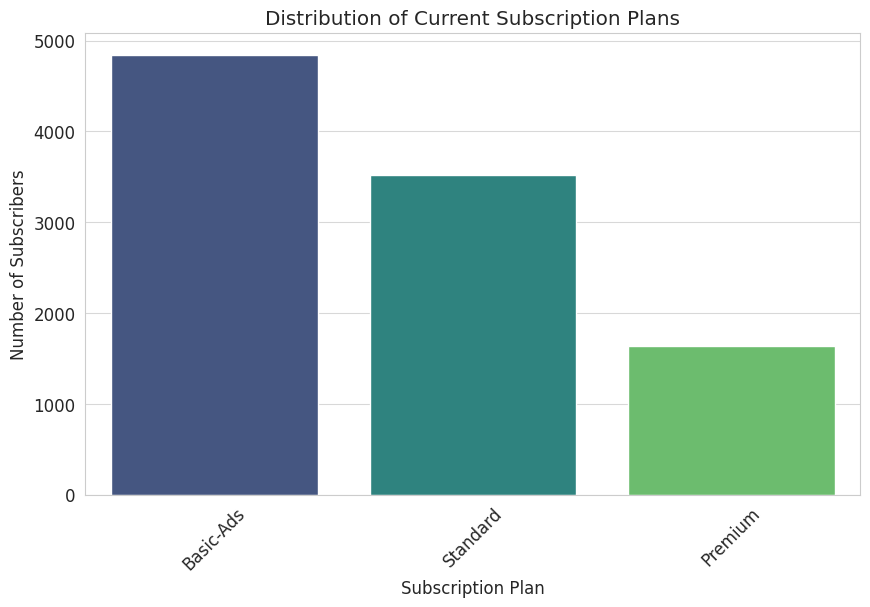


Current Plan Distribution:
current_plan
Basic-Ads    4846
Standard     3523
Premium      1631
Name: count, dtype: int64


In [13]:
# Calculate the value counts of the 'current_plan' column
plan_distribution = df_subscribers['current_plan'].value_counts()

# Visualize the distribution using a bar chart
plt.figure(figsize=(10, 6))
sns.barplot(x=plan_distribution.index, y=plan_distribution.values, palette='viridis')
plt.title('Distribution of Current Subscription Plans')
plt.xlabel('Subscription Plan')
plt.ylabel('Number of Subscribers')
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.75)
plt.show()

print("\nCurrent Plan Distribution:")
print(plan_distribution)

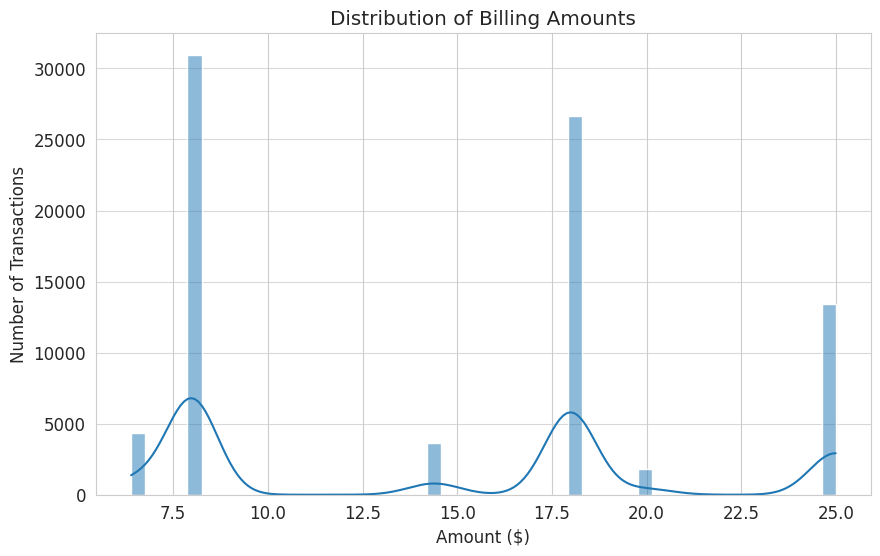


Billing Amount Statistics:
count    80809.000000
mean        14.584139
std          6.537780
min          6.390000
25%          7.990000
50%         17.990000
75%         17.990000
max         24.990000
Name: amount, dtype: float64


In [14]:
# Visualize the distribution of the 'amount' column using a histogram
plt.figure(figsize=(10, 6))
sns.histplot(df_billing['amount'], bins=50, kde=True)
plt.title('Distribution of Billing Amounts')
plt.xlabel('Amount ($)')
plt.ylabel('Number of Transactions')
plt.grid(axis='y', alpha=0.75)
plt.show()

print("\nBilling Amount Statistics:")
print(df_billing['amount'].describe())

/tmp/ipykernel_2935/2081001586.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=reason_code_distribution.values, y=reason_code_distribution.index, palette='viridis')


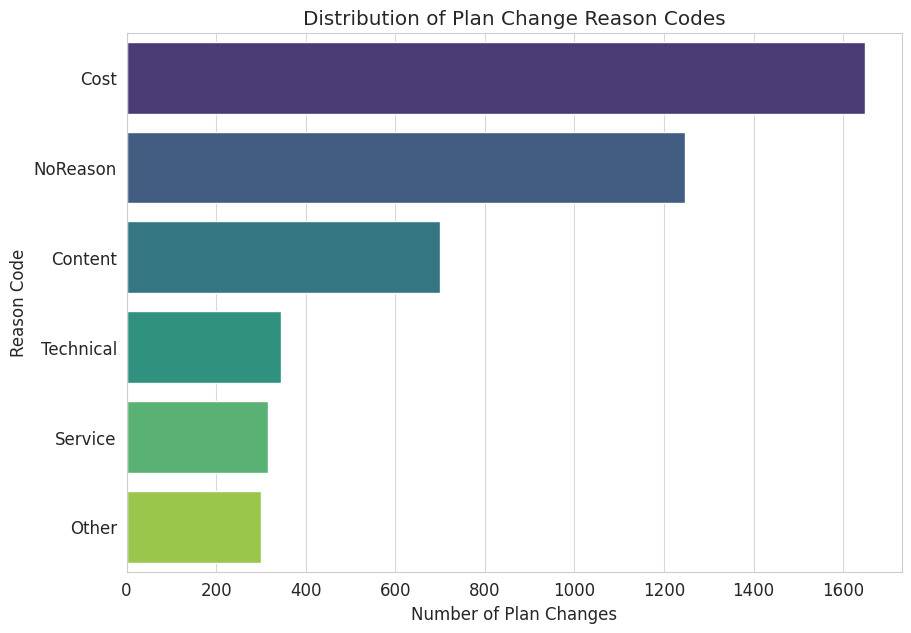


Plan Change Reason Code Distribution:
reason_code
Cost         1648
NoReason     1246
Content       699
Technical     345
Service       315
Other         301
Name: count, dtype: int64


In [15]:
# Calculate the value counts of the 'reason_code' column
reason_code_distribution = df_plan_changes['reason_code'].value_counts()

# Visualize the distribution using a horizontal bar chart
plt.figure(figsize=(10, 7))
sns.barplot(x=reason_code_distribution.values, y=reason_code_distribution.index, palette='viridis')
plt.title('Distribution of Plan Change Reason Codes')
plt.xlabel('Number of Plan Changes')
plt.ylabel('Reason Code')
plt.grid(axis='x', alpha=0.75)
plt.show()

print("\nPlan Change Reason Code Distribution:")
print(reason_code_distribution)

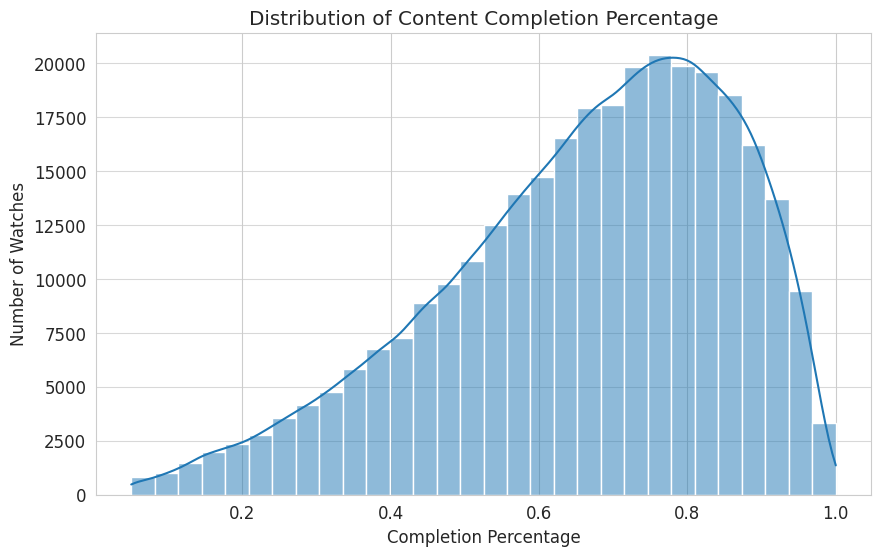

In [16]:
plt.figure(figsize=(10, 6))
sns.histplot(df_watch_history['completion_pct'].dropna(), bins=30, kde=True)
plt.title('Distribution of Content Completion Percentage')
plt.xlabel('Completion Percentage')
plt.ylabel('Number of Watches')
plt.grid(axis='y', alpha=0.75)
plt.show()

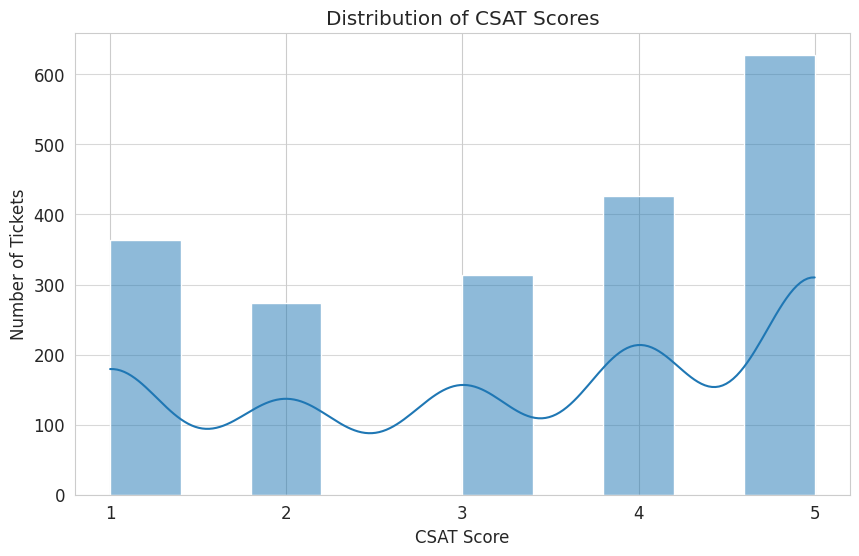

In [17]:
plt.figure(figsize=(10, 6))
sns.histplot(df_support_tickets['csat_score'].dropna(), bins=10, kde=True)
plt.title('Distribution of CSAT Scores')
plt.xlabel('CSAT Score')
plt.ylabel('Number of Tickets')
plt.xticks(range(1, 6))
plt.grid(axis='y', alpha=0.75)
plt.show()

/tmp/ipykernel_2935/1940706044.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=time_of_day_distribution.index, y=time_of_day_distribution.values, palette='viridis')


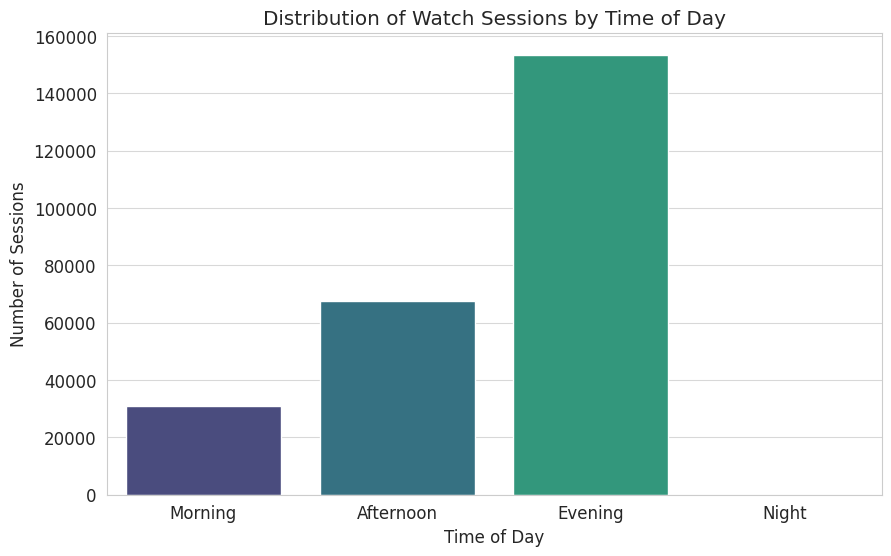


Time of Day Distribution:
time_of_day
Morning       30770
Afternoon     67450
Evening      153458
Night             0
Name: count, dtype: int64


In [18]:
# Calculate the value counts of the 'time_of_day' column
time_of_day_distribution = df_watch_history['time_of_day'].value_counts()

# Define a specific order for the time of day categories if desired (e.g., chronological)
time_of_day_order = ['Morning', 'Afternoon', 'Evening', 'Night']
# Reindex to ensure consistent order, filling missing categories with 0 if any
time_of_day_distribution = time_of_day_distribution.reindex(time_of_day_order, fill_value=0)

# Visualize the distribution using a bar chart
plt.figure(figsize=(10, 6))
sns.barplot(x=time_of_day_distribution.index, y=time_of_day_distribution.values, palette='viridis')
plt.title('Distribution of Watch Sessions by Time of Day')
plt.xlabel('Time of Day')
plt.ylabel('Number of Sessions')
plt.grid(axis='y', alpha=0.75)
plt.show()

print("\nTime of Day Distribution:")
print(time_of_day_distribution)

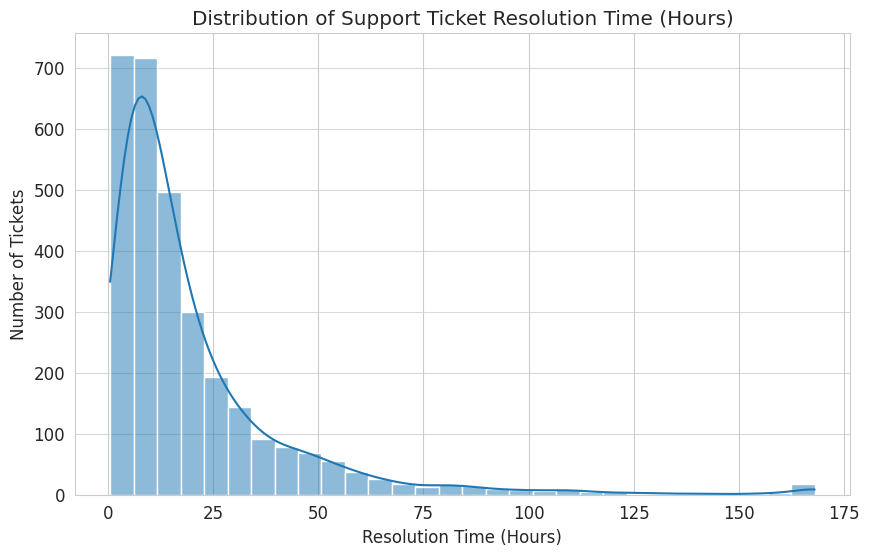


Resolution Time Statistics:
count    3056.000000
mean       20.224673
std        23.644539
min         0.500000
25%         6.300000
50%        12.400000
75%        24.200000
max       168.000000
Name: resolution_time_hours, dtype: float64


In [19]:
plt.figure(figsize=(10, 6))
sns.histplot(df_support_tickets['resolution_time_hours'].dropna(), bins=30, kde=True)
plt.title('Distribution of Support Ticket Resolution Time (Hours)')
plt.xlabel('Resolution Time (Hours)')
plt.ylabel('Number of Tickets')
plt.grid(axis='y', alpha=0.75)
plt.show()

print("\nResolution Time Statistics:")
print(df_support_tickets['resolution_time_hours'].describe())

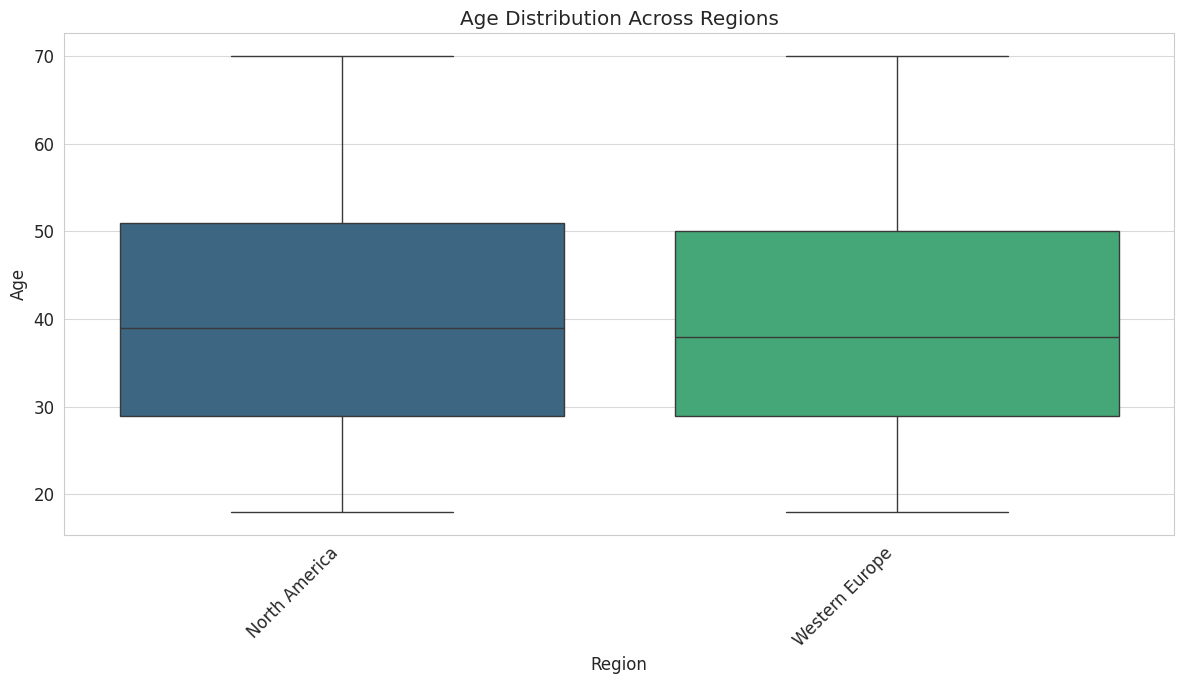


Summary Statistics of Age by Region:
                 count       mean        std   min   25%   50%   75%   max
region                                                                    
North America   5835.0  40.366067  13.996192  18.0  29.0  39.0  51.0  70.0
Western Europe  3886.0  39.910962  13.768870  18.0  29.0  38.0  50.0  70.0


In [20]:
plt.figure(figsize=(12, 7))
sns.boxplot(x='region', y='age', data=df_subscribers.dropna(subset=['age', 'region']), hue='region', palette='viridis', legend=False)
plt.title('Age Distribution Across Regions')
plt.xlabel('Region')
plt.ylabel('Age')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.75)
plt.tight_layout()
plt.show()

print("\nSummary Statistics of Age by Region:")
print(df_subscribers.groupby('region')['age'].describe())

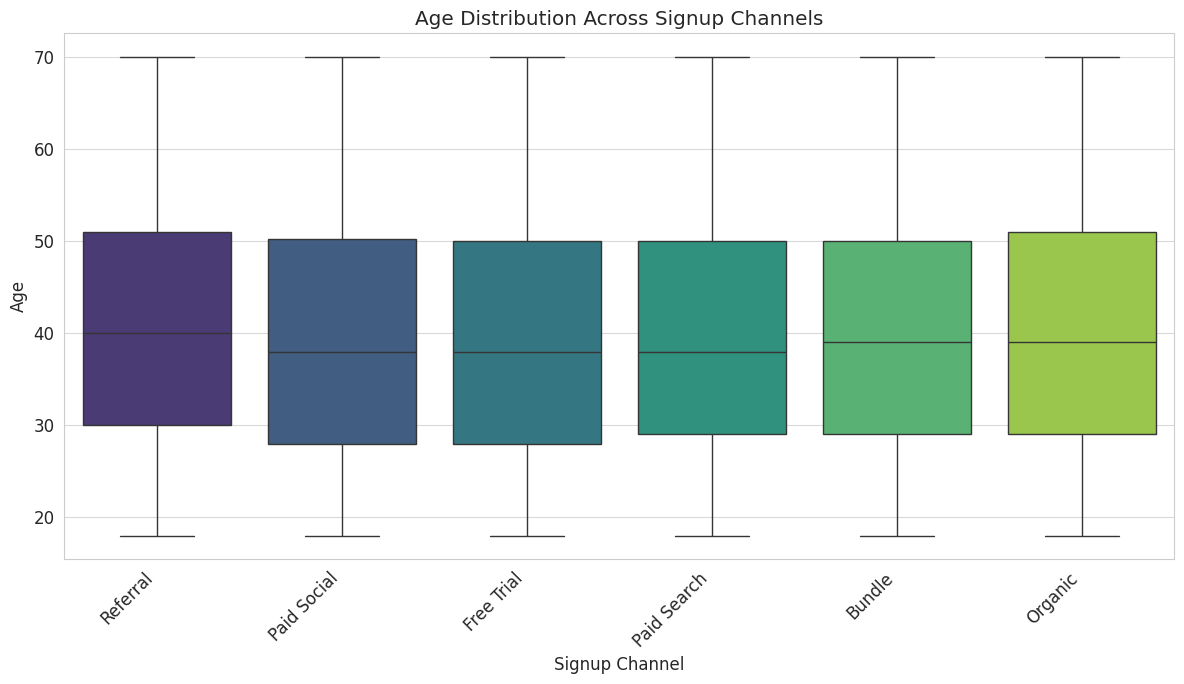


Summary Statistics of Age by Signup Channel:
                 count       mean        std   min   25%   50%    75%   max
signup_channel                                                             
Bundle           700.0  40.257143  13.716927  18.0  29.0  39.0  50.00  70.0
Free Trial      2222.0  39.853735  13.699046  18.0  28.0  38.0  50.00  70.0
Organic         2109.0  40.786155  14.025839  18.0  29.0  39.0  51.00  70.0
Paid Search     1721.0  39.858222  13.817780  18.0  29.0  38.0  50.00  70.0
Paid Social     2068.0  39.879594  14.186794  18.0  28.0  38.0  50.25  70.0
Referral         901.0  40.854606  13.769046  18.0  30.0  40.0  51.00  70.0


In [21]:
plt.figure(figsize=(12, 7))
sns.boxplot(x='signup_channel', y='age', data=df_subscribers.dropna(subset=['age', 'signup_channel']), hue='signup_channel', palette='viridis', legend=False)
plt.title('Age Distribution Across Signup Channels')
plt.xlabel('Signup Channel')
plt.ylabel('Age')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.75)
plt.tight_layout()
plt.show()

print("\nSummary Statistics of Age by Signup Channel:")
print(df_subscribers.groupby('signup_channel')['age'].describe())

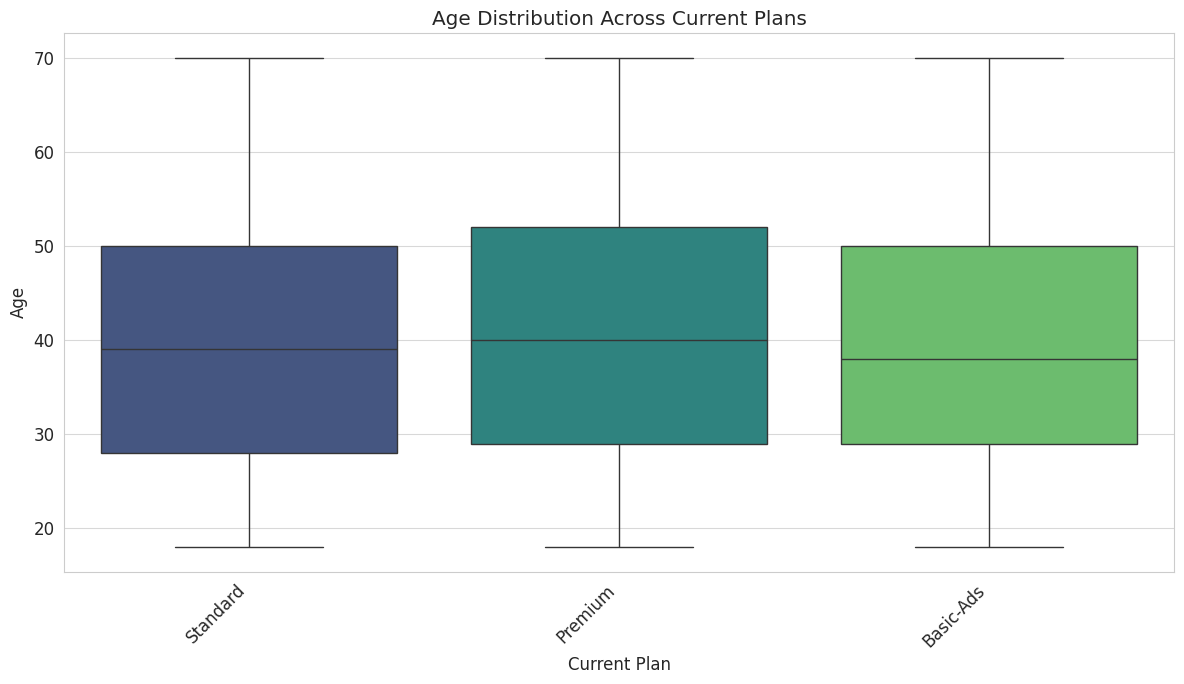


Summary Statistics of Age by Current Plan:
               count       mean        std   min   25%   50%   75%   max
current_plan                                                            
Basic-Ads     4708.0  40.027400  13.823015  18.0  29.0  38.0  50.0  70.0
Premium       1587.0  41.079395  14.066676  18.0  29.0  40.0  52.0  70.0
Standard      3426.0  39.984822  13.935296  18.0  28.0  39.0  50.0  70.0


In [22]:
plt.figure(figsize=(12, 7))
sns.boxplot(x='current_plan', y='age', data=df_subscribers.dropna(subset=['age', 'current_plan']), hue='current_plan', palette='viridis', legend=False)
plt.title('Age Distribution Across Current Plans')
plt.xlabel('Current Plan')
plt.ylabel('Age')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.75)
plt.tight_layout()
plt.show()

print("\nSummary Statistics of Age by Current Plan:")
print(df_subscribers.groupby('current_plan')['age'].describe())

/tmp/ipykernel_2935/3077181620.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


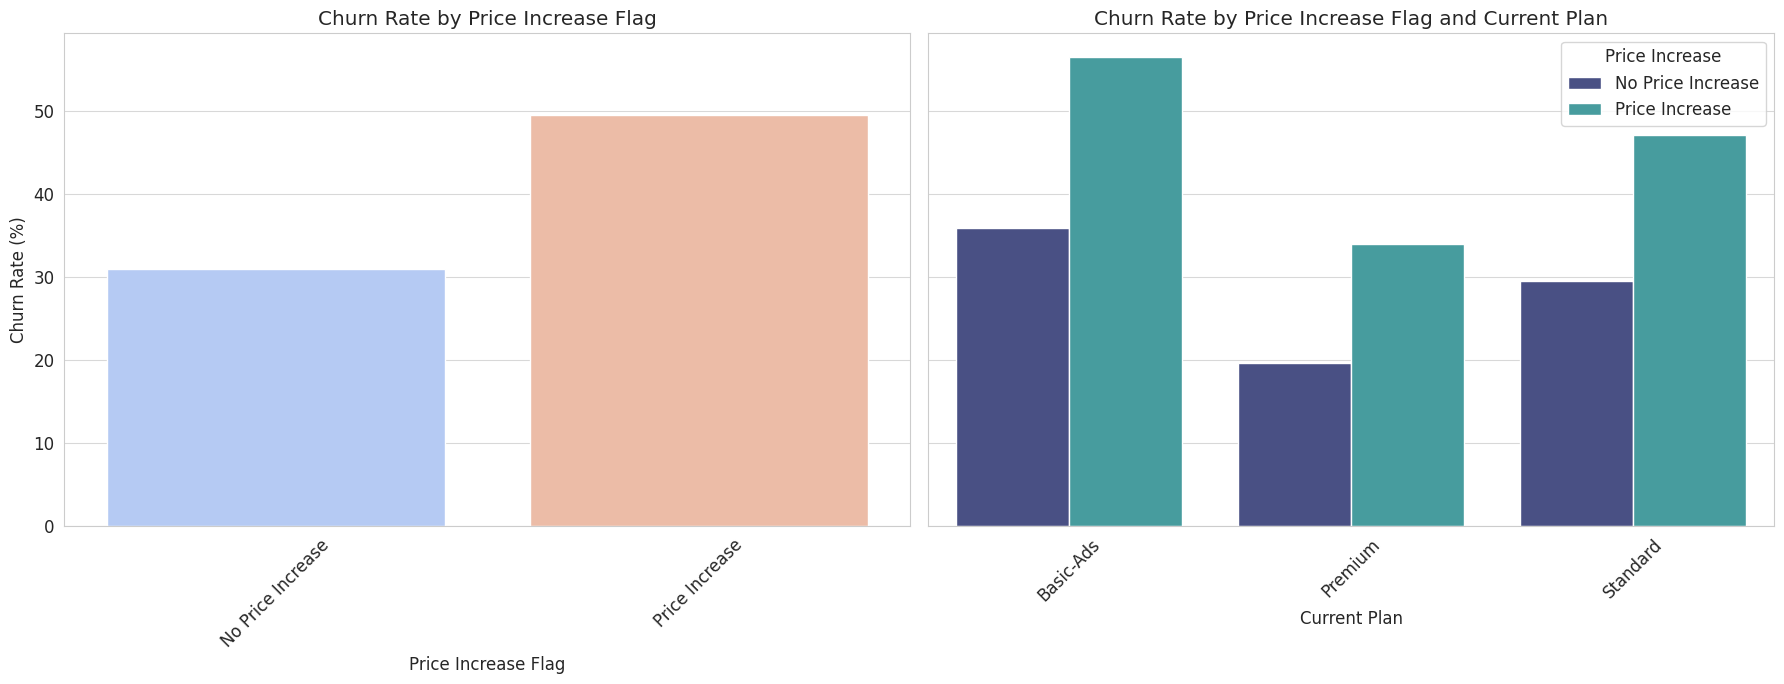

In [23]:
# Calculate churn rate by price_increase_flag
churn_by_price_flag = df_subscribers.groupby('price_increase_flag')['churn_status'].mean().reset_index()
churn_by_price_flag['churn_rate'] = churn_by_price_flag['churn_status'] * 100

# Calculate churn rate by price_increase_flag and current_plan
churn_by_price_flag_plan = df_subscribers.groupby(['price_increase_flag', 'current_plan'])['churn_status'].mean().reset_index()
churn_by_price_flag_plan['churn_rate'] = churn_by_price_flag_plan['churn_status'] * 100

# Convert price_increase_flag to descriptive labels for better readability in plots
churn_by_price_flag['price_increase_label'] = churn_by_price_flag['price_increase_flag'].map({0: 'No Price Increase', 1: 'Price Increase'})
churn_by_price_flag_plan['price_increase_label'] = churn_by_price_flag_plan['price_increase_flag'].map({0: 'No Price Increase', 1: 'Price Increase'})

# Create a two-panel figure
fig, axes = plt.subplots(1, 2, figsize=(18, 7), sharey=True)

# Plot 1: Churn rate by price increase flag
sns.barplot(
    x='price_increase_label',
    y='churn_rate',
    data=churn_by_price_flag,
    palette='coolwarm',
    ax=axes[0]
)
axes[0].set_title('Churn Rate by Price Increase Flag')
axes[0].set_xlabel('Price Increase Flag')
axes[0].set_ylabel('Churn Rate (%)')
axes[0].tick_params(axis='x', rotation=45)
axes[0].grid(axis='y', alpha=0.75)

# Plot 2: Churn rate by price increase flag and current plan (grouped bar chart)
sns.barplot(
    x='current_plan',
    y='churn_rate',
    hue='price_increase_label',
    data=churn_by_price_flag_plan,
    palette='mako',
    ax=axes[1]
)
axes[1].set_title('Churn Rate by Price Increase Flag and Current Plan')
axes[1].set_xlabel('Current Plan')
axes[1].set_ylabel('Churn Rate (%)')
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend(title='Price Increase')
axes[1].grid(axis='y', alpha=0.75)

plt.tight_layout()
plt.show()

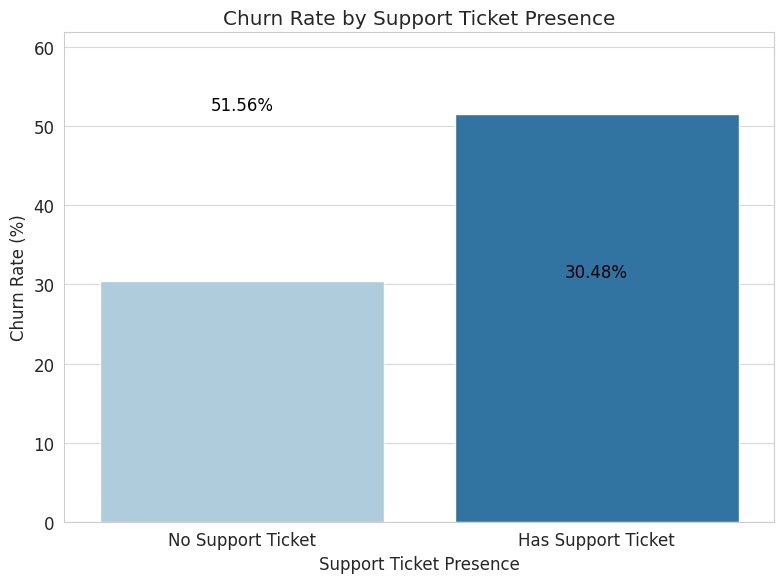

In [24]:
# Identify subscribers who have opened at least one support ticket
subscribers_with_tickets = df_support_tickets['subscriber_id'].unique()

# Create a new column in df_subscribers indicating ticket presence
# Use a temporary copy to avoid modifying original df_subscribers unexpectedly in current operation
df_subscribers_temp = df_subscribers.copy()
df_subscribers_temp['has_support_ticket'] = df_subscribers_temp['subscriber_id'].isin(subscribers_with_tickets)

# Convert boolean to a more descriptive string for plotting
df_subscribers_temp['has_support_ticket_label'] = df_subscribers_temp['has_support_ticket'].map({True: 'Has Support Ticket', False: 'No Support Ticket'})

# Calculate churn rate based on support ticket presence
churn_by_support_ticket = df_subscribers_temp.groupby('has_support_ticket_label')['churn_status'].mean().reset_index()
churn_by_support_ticket['churn_rate'] = churn_by_support_ticket['churn_status'] * 100

# Plot 1: Churn Rate by Support Ticket Presence
plt.figure(figsize=(8, 6))
sns.barplot(
    x='has_support_ticket_label',
    y='churn_rate',
    hue='has_support_ticket_label', # Assign x to hue as suggested by the warning
    data=churn_by_support_ticket,
    palette={'No Support Ticket': '#a6cee3', 'Has Support Ticket': '#1f78b4'}, # Map colors to hue categories
    order=['No Support Ticket', 'Has Support Ticket'],
    hue_order=['No Support Ticket', 'Has Support Ticket'], # Ensure consistent order for hue
    legend=False # Suppress the legend for hue as it's redundant with x-axis labels
)
plt.title('Churn Rate by Support Ticket Presence')
plt.xlabel('Support Ticket Presence')
plt.ylabel('Churn Rate (%)')
plt.tick_params(axis='x', rotation=0)
plt.ylim(0, churn_by_support_ticket['churn_rate'].max() * 1.2)
for index, row in churn_by_support_ticket.iterrows():
    plt.text(index, row.churn_rate + 0.5, f'{row.churn_rate:.2f}%', color='black', ha="center")
plt.grid(axis='y', alpha=0.75)
plt.tight_layout()
plt.show()

<Figure size 1200x700 with 0 Axes>

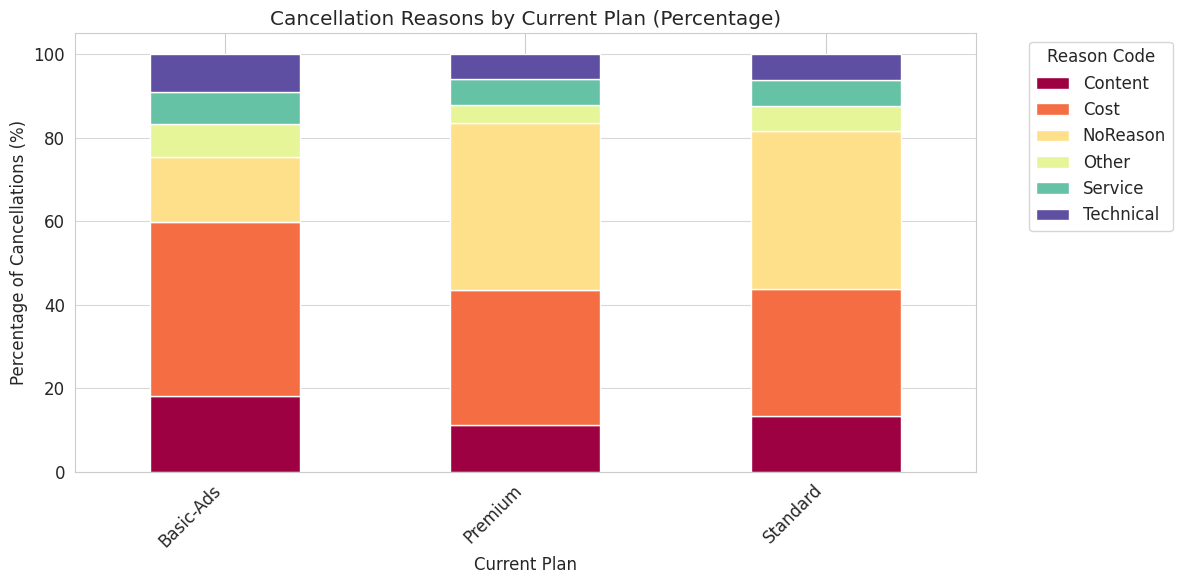


Cancellation Reasons by Current Plan (Percentage):
reason_code     Content       Cost   NoReason     Other   Service  Technical
current_plan                                                                
Basic-Ads     18.058076  41.833031  15.562613  7.849365  7.531760   9.165154
Premium       11.034483  32.413793  40.000000  4.310345  6.206897   6.034483
Standard      13.389831  30.395480  37.909605  5.819209  6.384181   6.101695


In [25]:
# Merge df_subscribers with df_plan_changes to get plan and reason code
# We are interested in cancellation reasons, so filter for 'cancelled' to_plan or reason codes
# For simplicity, let's merge and then filter for subscribers who have a reason_code

merged_churn_reasons = df_subscribers.merge(df_plan_changes[['subscriber_id', 'reason_code', 'change_type']],
                                          on='subscriber_id',
                                          how='left')

# Filter for actual cancellations or plan changes that have a reason code
# Assuming 'reason_code' is present for cancellations and relevant plan changes
# If 'change_type' 'cancelled' is what defines cancellation, we can use that.
# The prompt asks for 'cancellation reason', implying we should focus on churned subscribers who also have a reason code.
# Let's consider reason_code to imply a change/cancellation for simplicity in this visualization.

# Create a cross-tabulation of 'current_plan' and 'reason_code'
# Fill any NaN in reason_code that might come from subscribers who didn't change plan or didn't provide a reason
# Let's focus on actual reasons provided, so drop NaN reason_codes

plan_reason_cross = merged_churn_reasons.dropna(subset=['reason_code']).groupby(['current_plan', 'reason_code']).size().unstack(fill_value=0)

# Normalize the data to show percentages within each plan
plan_reason_percent = plan_reason_cross.div(plan_reason_cross.sum(axis=1), axis=0) * 100

# Plotting the stacked bar chart
plt.figure(figsize=(12, 7))
plan_reason_percent.plot(kind='bar', stacked=True, colormap='Spectral')

plt.title('Cancellation Reasons by Current Plan (Percentage)')
plt.xlabel('Current Plan')
plt.ylabel('Percentage of Cancellations (%)')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Reason Code', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(axis='y', alpha=0.75)
plt.tight_layout()
plt.show()

print("\nCancellation Reasons by Current Plan (Percentage):")
print(plan_reason_percent)

/tmp/ipykernel_2935/1119901880.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='issue_category', y='resolution_time_hours', data=df_support_tickets, palette='viridis')


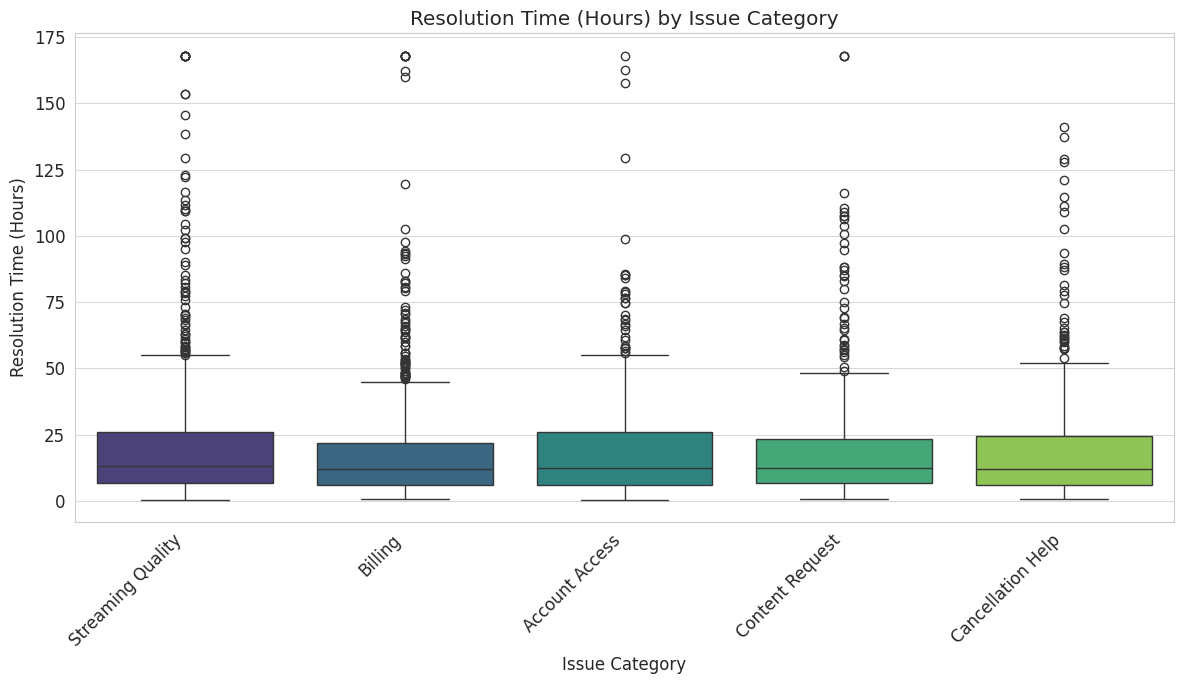

In [26]:
plt.figure(figsize=(12, 7))
sns.boxplot(x='issue_category', y='resolution_time_hours', data=df_support_tickets, palette='viridis')
plt.title('Resolution Time (Hours) by Issue Category')
plt.xlabel('Issue Category')
plt.ylabel('Resolution Time (Hours)')
plt.xticks(rotation=45, ha='right') # Rotate x-axis labels for better readability
plt.grid(axis='y', alpha=0.75)
plt.tight_layout()
plt.show()

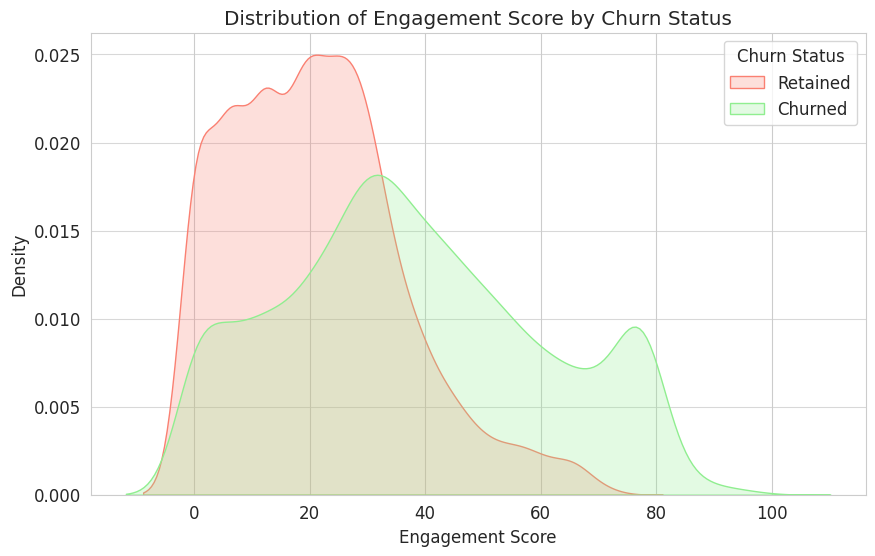

In [27]:
merged_df = df_subscribers.merge(watch_summary[['subscriber_id', 'engagement_score']], on='subscriber_id', how='left')
merged_df['engagement_score'] = merged_df['engagement_score'].fillna(0)

plt.figure(figsize=(10, 6))
sns.kdeplot(data=merged_df, x='engagement_score', hue='churn_status', fill=True, common_norm=False,
            palette={0: 'lightgreen', 1: 'salmon'},
            hue_order=[0, 1])
plt.title('Distribution of Engagement Score by Churn Status')
plt.xlabel('Engagement Score')
plt.ylabel('Density')
plt.legend(title='Churn Status', labels=['Retained', 'Churned'])
plt.grid(axis='y', alpha=0.75)
plt.show()

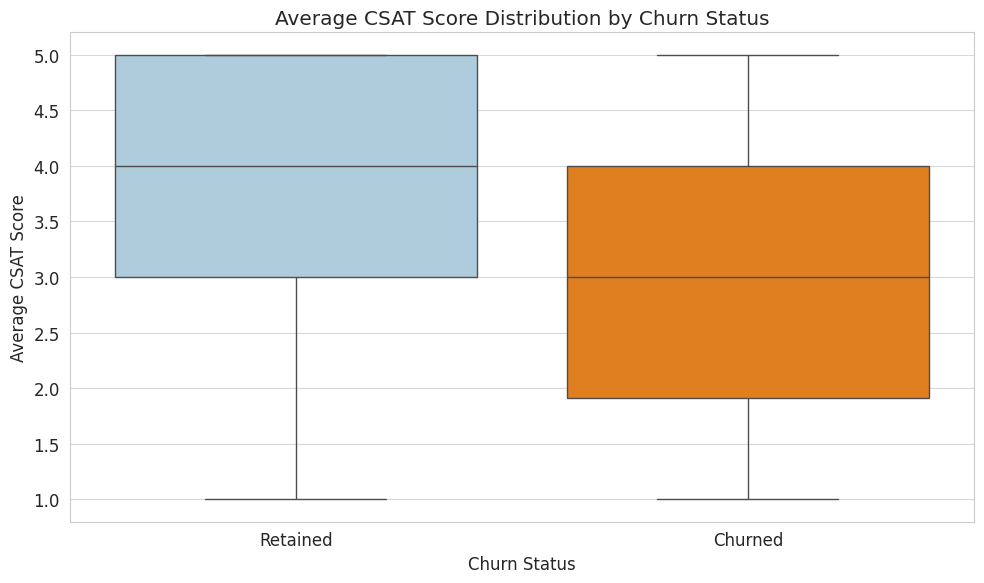


Summary Statistics for Average CSAT Score by Churn Status:
             count      mean      std  min       25%  50%  75%  max
churn_label                                                        
Churned      812.0  2.859195  1.41131  1.0  1.916667  3.0  4.0  5.0
Retained     754.0  3.859195  1.18501  1.0  3.000000  4.0  5.0  5.0


In [28]:
# Calculate the average CSAT score for each subscriber
avg_csat_per_subscriber = df_support_tickets.groupby('subscriber_id')['csat_score'].mean().reset_index()
avg_csat_per_subscriber.rename(columns={'csat_score': 'avg_csat_score'}, inplace=True)

# Merge with df_subscribers to get churn status
csat_churn_df = df_subscribers.merge(avg_csat_per_subscriber, on='subscriber_id', how='left')

# Map churn_status to descriptive labels
csat_churn_df['churn_label'] = csat_churn_df['churn_status'].map({0: 'Retained', 1: 'Churned'})

# Visualize the relationship between CSAT and churn status using a box plot
plt.figure(figsize=(10, 6))
sns.boxplot(x='churn_label', y='avg_csat_score', data=csat_churn_df.dropna(subset=['avg_csat_score']),
            hue='churn_label', palette={'Retained': '#a6cee3', 'Churned': '#ff7f00'}, legend=False)
plt.title('Average CSAT Score Distribution by Churn Status')
plt.xlabel('Churn Status')
plt.ylabel('Average CSAT Score')
plt.grid(axis='y', alpha=0.75)
plt.tight_layout()
plt.show()

print("\nSummary Statistics for Average CSAT Score by Churn Status:")
print(csat_churn_df.groupby('churn_label')['avg_csat_score'].describe())

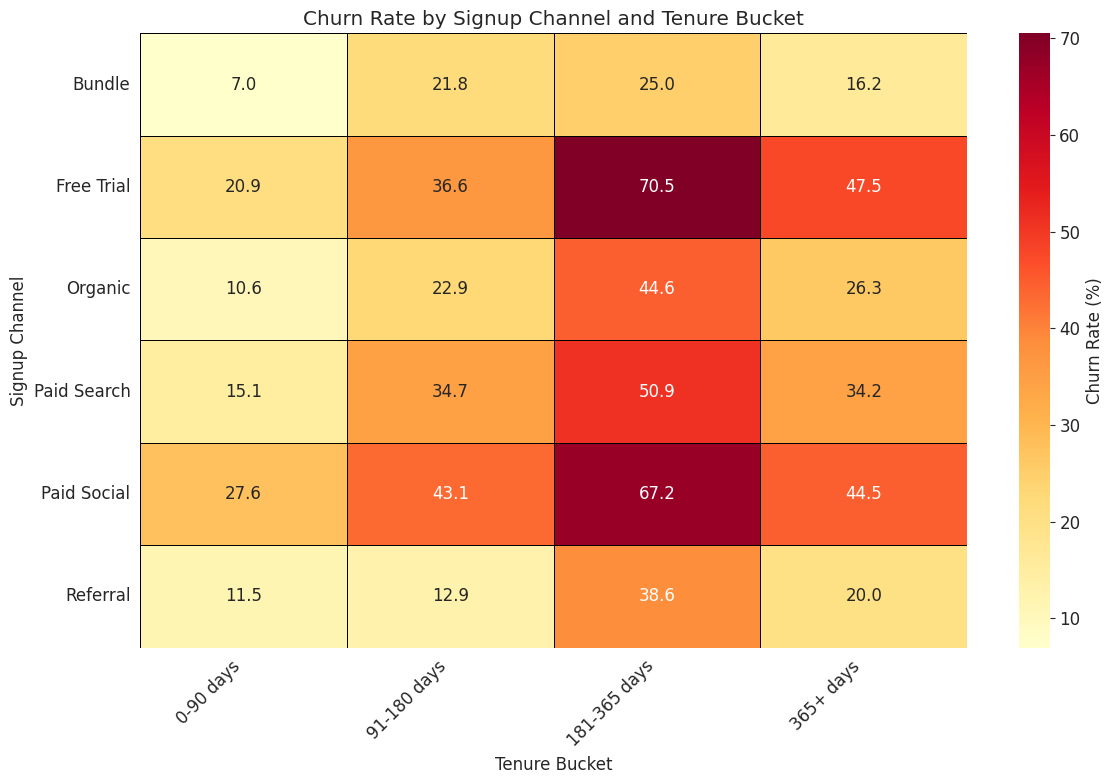


Churn Rate by Signup Channel and Tenure Bucket:
tenure_bucket   0-90 days  91-180 days  181-365 days  365+ days
signup_channel                                                 
Bundle           6.976744    21.794872     25.000000  16.166282
Free Trial      20.925553    36.627907     70.509383  47.469880
Organic         10.622711    22.916667     44.604317  26.348710
Paid Search     15.073529    34.722222     50.903614  34.189723
Paid Social     27.628866    43.103448     67.187500  44.546288
Referral        11.486486    12.857143     38.554217  20.036430


In [29]:
merged_df_tenure = df_subscribers.copy()

# Define 'today' as the latest signup date in the dataset for a consistent reference point
today_date = merged_df_tenure['signup_date'].max()
merged_df_tenure['tenure_days'] = (today_date - merged_df_tenure['signup_date']).dt.days

# Create specific tenure buckets based on the user's request
tenure_bins = [0, 90, 180, 365, merged_df_tenure['tenure_days'].max() + 1] # Ensure the last bin covers the max tenure
tenure_labels = ['0-90 days', '91-180 days', '181-365 days', '365+ days']

merged_df_tenure['tenure_bucket'] = pd.cut(
    merged_df_tenure['tenure_days'],
    bins=tenure_bins,
    labels=tenure_labels,
    right=False # Interval includes the left boundary, excludes the right
)

# Calculate churn rate by signup_channel and tenure_bucket
churn_by_channel_tenure = merged_df_tenure.groupby(['signup_channel', 'tenure_bucket'], observed=False)['churn_status'].mean().unstack()

# Convert to percentage
churn_by_channel_tenure = churn_by_channel_tenure * 100

# Define the order for tenure buckets (explicitly, as pd.cut labels are ordered by default)
tenure_order = tenure_labels
churn_by_channel_tenure = churn_by_channel_tenure[tenure_order]

# Plotting the heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(
    churn_by_channel_tenure,
    annot=True,      # Show the churn rate values on the heatmap
    fmt=".1f",       # Format annotations to one decimal place
    cmap='YlOrRd',   # Colormap for churn rate, higher values are redder
    linewidths=.5,   # Add lines between cells
    linecolor='black',
    cbar_kws={'label': 'Churn Rate (%)'}
)
plt.title('Churn Rate by Signup Channel and Tenure Bucket')
plt.xlabel('Tenure Bucket')
plt.ylabel('Signup Channel')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

print("\nChurn Rate by Signup Channel and Tenure Bucket:")
print(churn_by_channel_tenure)

In [30]:
print("Engagement Score Percentile Distribution (20th, 40th, 60th, 80th):")
print(watch_summary['engagement_score'].describe(percentiles=[0.20, 0.40, 0.60, 0.80]))

Engagement Score Percentile Distribution (20th, 40th, 60th, 80th):
count    9865.000000
mean       32.487277
std        21.710127
min         0.000000
20%        12.312697
40%        24.677785
50%        29.563410
60%        34.611415
80%        51.173752
max        98.360263
Name: engagement_score, dtype: float64


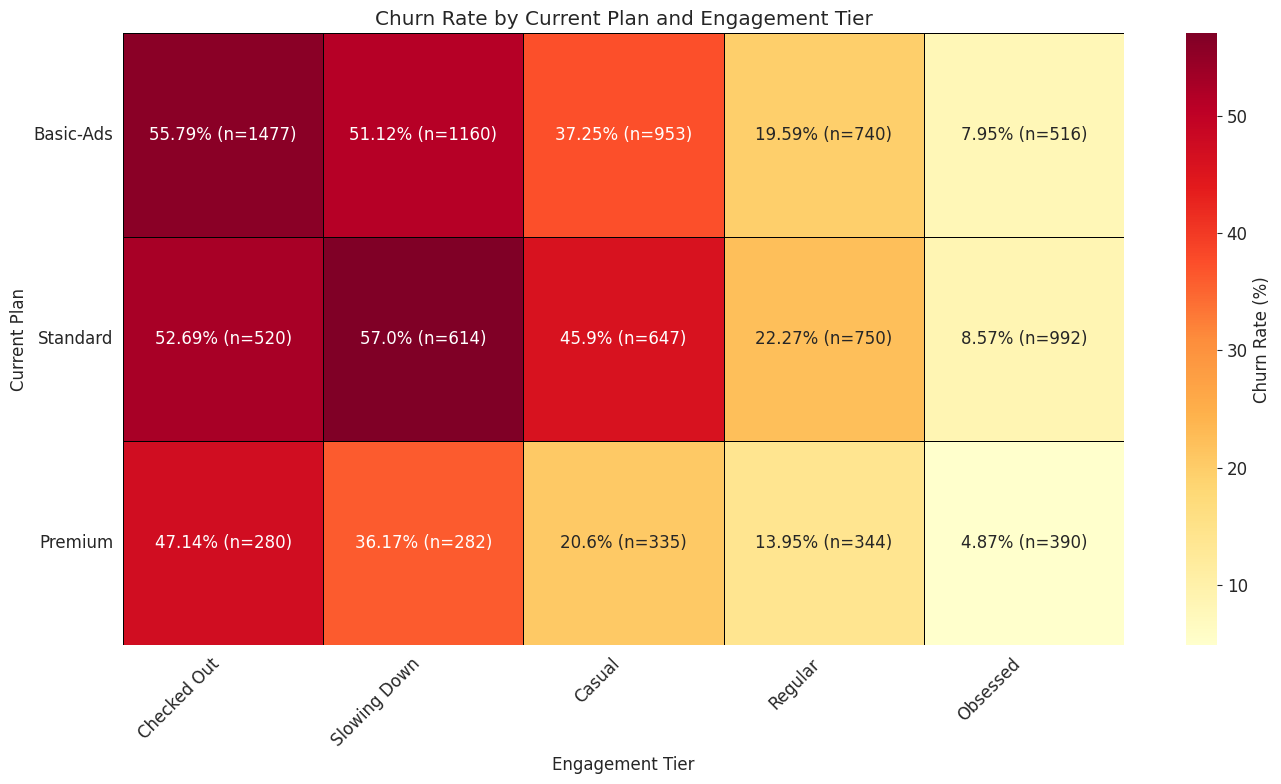


Churn Rate and Subscriber Count by Current Plan and Engagement Tier:
   current_plan engagement_score_tier  churn_rate  subscriber_count
0     Basic-Ads           Checked Out   55.788761              1477
1     Basic-Ads          Slowing Down   51.120690              1160
2     Basic-Ads                Casual   37.250787               953
3     Basic-Ads               Regular   19.594595               740
4     Basic-Ads              Obsessed    7.945736               516
5       Premium           Checked Out   47.142857               280
6       Premium          Slowing Down   36.170213               282
7       Premium                Casual   20.597015               335
8       Premium               Regular   13.953488               344
9       Premium              Obsessed    4.871795               390
10     Standard           Checked Out   52.692308               520
11     Standard          Slowing Down   57.003257               614
12     Standard                Casual   45.904

In [31]:
# Ensure merged_df is up-to-date and contains engagement_score, current_plan, and churn_status
# (Assuming merged_df is already created and updated with engagement_score as per previous steps)
merged_df = df_subscribers.merge(watch_summary[['subscriber_id', 'engagement_score']], on='subscriber_id', how='left')
merged_df['engagement_score'] = merged_df['engagement_score'].fillna(0)

# Define custom engagement score tiers as per the updated prompt
engagement_bins = [0, 13, 26, 36, 52, 100.1] # Added 100.1 to ensure 100 is included in the last bin
engagement_labels = ['Checked Out', 'Slowing Down', 'Casual', 'Regular', 'Obsessed']

merged_df['engagement_score_tier'] = pd.cut(
    merged_df['engagement_score'],
    bins=engagement_bins,
    labels=engagement_labels,
    right=False, # Interval includes the left boundary, excludes the right
    include_lowest=True # Include the lowest value (0)
)

# Group by 'current_plan' and 'engagement_score_tier' and calculate churn rate and subscriber count
churn_engagement_plan = merged_df.groupby(['current_plan', 'engagement_score_tier'], observed=False).agg(
    churn_rate=('churn_status', 'mean'),
    subscriber_count=('subscriber_id', 'count')
).reset_index()

churn_engagement_plan['churn_rate'] = churn_engagement_plan['churn_rate'] * 100 # Convert to percentage

# Pivot the table for the heatmap, for churn rate values
churn_rate_pivot = churn_engagement_plan.pivot_table(
    index='current_plan',
    columns='engagement_score_tier',
    values='churn_rate',
    observed=False
)

# Pivot the table for subscriber counts (for annotations)
subscriber_count_pivot = churn_engagement_plan.pivot_table(
    index='current_plan',
    columns='engagement_score_tier',
    values='subscriber_count',
    observed=False
)

# Define the order for columns (engagement tiers) and rows (plans)
engagement_tier_order = ['Checked Out', 'Slowing Down', 'Casual', 'Regular', 'Obsessed']
plan_order = ['Basic-Ads', 'Standard', 'Premium']

# Reindex pivots to ensure consistent order
churn_rate_pivot = churn_rate_pivot.reindex(index=plan_order, columns=engagement_tier_order)
subscriber_count_pivot = subscriber_count_pivot.reindex(index=plan_order, columns=engagement_tier_order)

# Create annotation matrix: churn rate (%) and subscriber count
annotations = (churn_rate_pivot.round(2).astype(str) + '% (n=' + subscriber_count_pivot.astype(int).astype(str) + ')')

# Plotting the heatmap
plt.figure(figsize=(14, 8))
sns.heatmap(
    churn_rate_pivot,
    annot=annotations,
    fmt='s', # Use 's' to format annotations as strings
    cmap='YlOrRd',
    linewidths=.5,
    linecolor='black',
    cbar_kws={'label': 'Churn Rate (%)'}
)
plt.title('Churn Rate by Current Plan and Engagement Tier')
plt.xlabel('Engagement Tier')
plt.ylabel('Current Plan')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

print("\nChurn Rate and Subscriber Count by Current Plan and Engagement Tier:")
print(churn_engagement_plan)

In [32]:
numerical_features = [
    'age',
    'household_size',
    'tenure_days',
    'engagement_score',
    'days_since_last_session',
    'avg_resolution_time_hours',
    'avg_csat_score',
    'total_support_tickets',
    'avg_billing_amount',
    'total_transactions',
    'sum_retry_count'
]

categorical_features = [
    'gender',
    'region',
    'country',
    'current_plan',
    'signup_channel',
    'device_primary',
    'plan_at_billing',
    'payment_status',
    'payment_method',
    'from_plan',
    'to_plan',
    'change_type',
    'reason_code',
    'issue_category',
    'resolution_status',
    'contact_channel',
    'content_category',
    'device_used',
    'time_of_day'
]

binary_features = [
    'churn_status',
    'price_increase_flag',
    'is_resub',
    'discount_applied',
    'has_support_ticket'
]

print("Numerical Features:", numerical_features)
print("\nCategorical Features:", categorical_features)
print("\nBinary Features:", binary_features)

Numerical Features: ['age', 'household_size', 'tenure_days', 'engagement_score', 'days_since_last_session', 'avg_resolution_time_hours', 'avg_csat_score', 'total_support_tickets', 'avg_billing_amount', 'total_transactions', 'sum_retry_count']

Categorical Features: ['gender', 'region', 'country', 'current_plan', 'signup_channel', 'device_primary', 'plan_at_billing', 'payment_status', 'payment_method', 'from_plan', 'to_plan', 'change_type', 'reason_code', 'issue_category', 'resolution_status', 'contact_channel', 'content_category', 'device_used', 'time_of_day']

Binary Features: ['churn_status', 'price_increase_flag', 'is_resub', 'discount_applied', 'has_support_ticket']


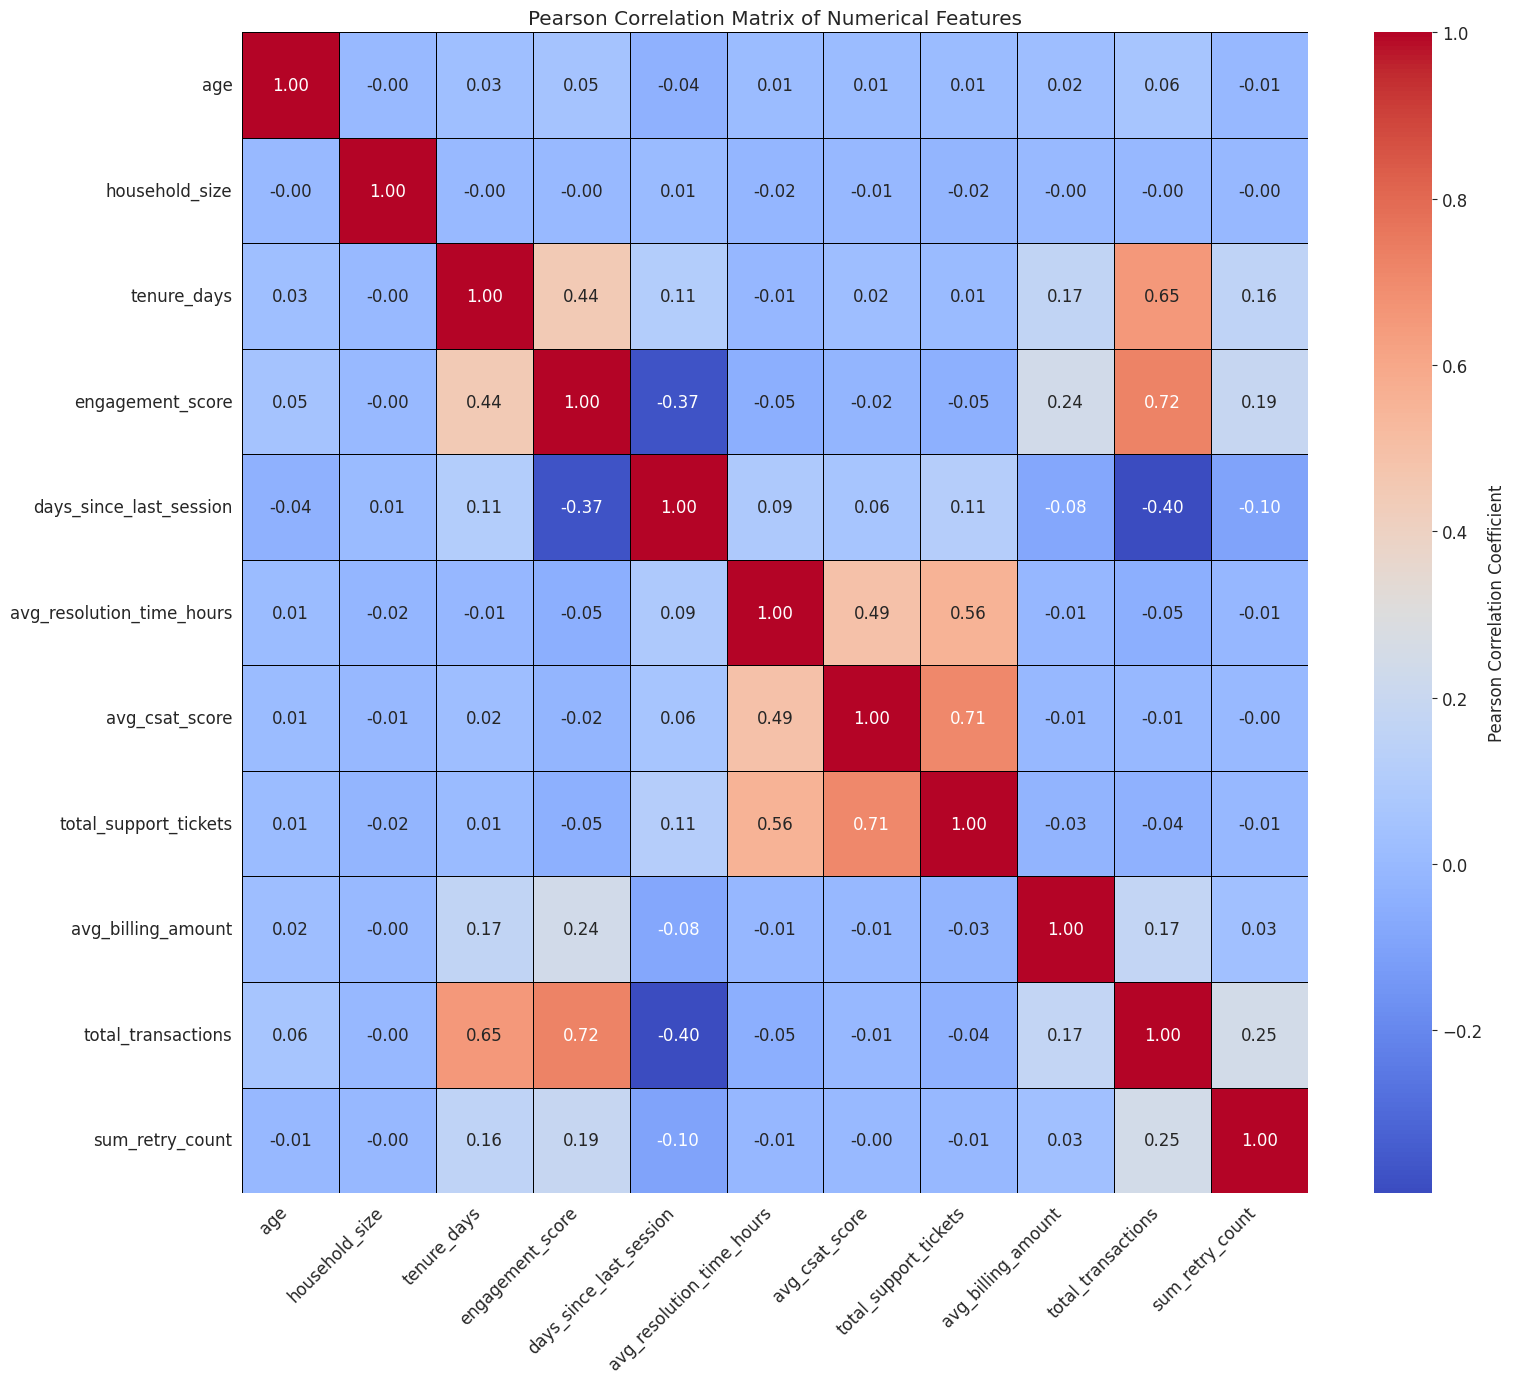

In [33]:
# Ensure 'tenure_days' is calculated on merged_df
today_date_sub = merged_df['signup_date'].max()
merged_df['tenure_days'] = (today_date_sub - merged_df['signup_date']).dt.days

# Start with merged_df, which contains df_subscribers data along with engagement_score and tenure_days.
subscriber_features_df_temp = merged_df[['subscriber_id', 'age', 'household_size', 'tenure_days', 'engagement_score']].copy()

# Calculate days since last session
today_date_wh = df_watch_history['session_date'].max()
latest_activity_date = df_watch_history.groupby('subscriber_id')['session_date'].max().reset_index()
latest_activity_date.columns = ['subscriber_id', 'last_session_date']
latest_activity_date['days_since_last_session'] = (today_date_wh - latest_activity_date['last_session_date']).dt.days
subscriber_features_df_temp = subscriber_features_df_temp.merge(latest_activity_date[['subscriber_id', 'days_since_last_session']], on='subscriber_id', how='left')

# Aggregate df_support_tickets numerical features
support_summary_corr = df_support_tickets.groupby('subscriber_id').agg(
    avg_resolution_time_hours=('resolution_time_hours', 'mean'),
    avg_csat_score=('csat_score', 'mean'),
    total_support_tickets=('ticket_id', 'count')
).reset_index()
subscriber_features_df_temp = subscriber_features_df_temp.merge(support_summary_corr, on='subscriber_id', how='left')

# Aggregate df_billing numerical features
billing_summary_corr = df_billing.groupby('subscriber_id').agg(
    avg_billing_amount=('amount', 'mean'),
    total_transactions=('transaction_id', 'count'),
    sum_retry_count=('retry_count', 'sum')
).reset_index()
subscriber_features_df_temp = subscriber_features_df_temp.merge(billing_summary_corr, on='subscriber_id', how='left')

# Select only the numerical features from the prompt's list
correlation_df = subscriber_features_df_temp[numerical_features].copy()

# Fill NaNs with 0 for calculation, assuming absence means zero for these metrics.
correlation_df = correlation_df.fillna(0)

# Calculate the Pearson correlation matrix
correlation_matrix = correlation_df.corr(method='pearson')

# Visualize the correlation matrix as a heatmap
plt.figure(figsize=(16, 14))
sns.heatmap(
    correlation_matrix,
    annot=True,      # Show the correlation values on the heatmap
    fmt=".2f",       # Format annotations to two decimal places
    cmap="coolwarm", # Choose a diverging colormap
    linewidths=.5,   # Add lines between cells
    linecolor='black',
    cbar_kws={'label': 'Pearson Correlation Coefficient'}
)
plt.title('Pearson Correlation Matrix of Numerical Features')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()